# Quantum-Secure Fraud Detection System
## Layer 2 — Classical, Post-Quantum, and Simulated Quantum-Secure Communication Research

This notebook does **not** begin as an isolated cryptography tutorial. It begins with Layer 1's real output and
follows it through the actual Layer 2 pipeline implemented in `src/security/`. Every table and figure below loads
a real artifact from `results/layer2/`, `results/integration/`, or `docs/research/layer2/` — nothing is
hand-typed from memory.

**BB84 in this project is a software SIMULATION.** No physical quantum channel, no hardware QKD deployment, and
no production key-distribution security claim is made anywhere in this notebook.

## 1. Layer 2 Objective

Given a transaction's fraud-risk assessment from Layer 1, select and apply an appropriate cryptographic security
profile, and empirically characterize the trade-off between how well that routing targets real fraud
(`docs/protocols/LAYER2_INTEGRATION_PROTOCOL.md`'s Fraud-Weighted Coverage) and its computational/communication
cost.

## 2. Overall QSFD Architecture

```mermaid
graph TD
    A[Transaction] --> B[Preprocessing]
    B --> C[Layer 1: classical + quantum research]
    C --> D[FraudAssessment]
    D --> E[SecurityContext]
    E --> F[SecurityPolicyEngine]
    F --> G[SecurityProfile]
    G --> H[Protected Transaction]
    H --> I[Audit]
```

![Overall QSFD architecture](../artifacts/figures/diagrams/overall_architecture.png)

## 3. Threat Model

Per the project's source SRS (`docs/project/PROJECT_REQUIREMENTS_TRACEABILITY.md`), Layer 2 addresses two
*different* threat classes:
- **Classical threats**: eavesdropping, tampering, forgery -- addressed by AES-256-GCM (confidentiality +
  integrity) and digital signatures (authenticity).
- **Future quantum threats**: Shor's algorithm breaking RSA/ECC, Grover's algorithm halving symmetric key
  strength -- addressed by migrating key establishment and signatures to standardized post-quantum algorithms.
  **Fraud risk and quantum-cryptographic threat are different risk dimensions** -- a low-fraud-risk transaction
  is not thereby "quantum-safe-exempt."

**Why Layer 2 exists as a separate research question**: fraud detection and cryptographic security address
different threats entirely. Layer 2 investigates *"how can transaction-risk intelligence interact with
quantum-safe security without conflating fraud risk and cryptographic threat?"*

![Refined architecture: fraud risk vs cryptographic risk](../artifacts/figures/diagrams/refined_fraud_vs_crypto_risk.png)

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd() / "02_Layer2_Quantum_Secure_Cryptography_Research.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

RESULTS_L2 = ROOT / "results" / "layer2"
RESULTS_INT = ROOT / "results" / "integration"

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
print(f"Repository root resolved to: {ROOT}")
assert (ROOT / "src" / "security").exists()

Repository root resolved to: D:\Quantum Secure Fraud Detection System


## 4-8. Layer 1 -> Layer 2 Contract, SecurityContext, SecurityPolicyEngine

The contract is `FraudAssessment` (`src/fraud_engine/schemas.py`, unchanged by any Layer 2 work) ->
`SecurityContext.from_fraud_assessment(...)` (`src/security/integration/schemas.py`). No Layer 2 code branches on
which model produced the assessment.

In [2]:
from src.fraud_engine.schemas import FraudAssessment
from src.security.integration.schemas import SecurityContext
from src.security.policy.security_selector import CategoricalPolicy, ContinuousPolicy, ALGORITHMS_BY_PROFILE

example = FraudAssessment(transaction_id="demo-1", fraud_probability=0.85, fraud_prediction=1,
                            risk_score=85.0, risk_level="HIGH", model_name="xgboost", model_version="v1",
                            threshold=0.581019)
ctx = SecurityContext.from_fraud_assessment(example)
decision = CategoricalPolicy().decide(ctx)
print("SecurityContext:", ctx.to_dict())
print("\nSecurityDecision:", decision.to_dict())

SecurityContext: {'transaction_id': 'demo-1', 'fraud_probability': 0.85, 'fraud_prediction': 1, 'risk_score': 85.0, 'risk_level': 'HIGH', 'model_name': 'xgboost', 'model_version': 'v1', 'threshold': 0.581019, 'top_contributing_features': [], 'transaction_sensitivity': 'standard', 'quantum_safe_mode': False, 'timestamp': '2026-10-07T06:54:40.653173+00:00'}

SecurityDecision: {'transaction_id': 'demo-1', 'profile': 'HYBRID_MAXIMUM', 'reason': 'categorical routing: risk_level=HIGH -> HYBRID_MAXIMUM', 'policy_version': 'adaptive_security_v1-categorical', 'layer1_inputs_used': {'risk_level': 'HIGH', 'transaction_sensitivity': 'standard'}, 'algorithms': {'key_establishment': 'ECDH-P256 + ML-KEM-768 (hybrid KDF)', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65 + SLH-DSA-SHA2-128s (dual signature)'}, 'timestamp': '2026-10-07T06:54:40.653237+00:00'}


## 9. Baseline Security Principle

**Every profile, including BASELINE, uses full AES-256-GCM plus a real key-establishment algorithm.** Fraud risk
controls only *additional* protection layered on top -- never a weakened baseline. This is enforced in code and
tested (`tests/test_security_integration.py::test_categorical_policy_never_weakens_low_risk_below_baseline`).

In [3]:
for profile, algos in ALGORITHMS_BY_PROFILE.items():
    print(f"{profile:18s}: {algos}")

BASELINE          : {'key_establishment': 'ECDH-P256', 'symmetric': 'AES-256-GCM', 'signature': 'ECDSA-P256'}
PQC_ENHANCED      : {'key_establishment': 'ML-KEM-768', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65'}
HYBRID_MAXIMUM    : {'key_establishment': 'ECDH-P256 + ML-KEM-768 (hybrid KDF)', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65 + SLH-DSA-SHA2-128s (dual signature)'}
QKD_EXPERIMENTAL  : {'key_establishment': 'ECDH-P256 + ML-KEM-768 (hybrid KDF) + BB84-simulated key material', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65 + SLH-DSA-SHA2-128s (dual signature)'}


## 10-14. Classical Cryptography and Post-Quantum Cryptography

### Standardization terminology mapping

| Project/proposal name | Current standard (used in code) |
|---|---|
| CRYSTALS-Kyber | **ML-KEM** (FIPS 203) |
| CRYSTALS-Dilithium | **ML-DSA** (FIPS 204) |
| SPHINCS+ | **SLH-DSA** (FIPS 205) |

These are the same algorithms under their standardized names, not different unrelated schemes.

### KEM (Key Encapsulation Mechanism)

$$(pk, sk) \leftarrow \text{KeyGen}() \qquad (c, K) \leftarrow \text{Encaps}(pk) \qquad K' \leftarrow \text{Decaps}(sk, c) \qquad K = K'$$

### Digital signature

$$\sigma \leftarrow \text{Sign}(sk, m) \qquad \text{Verify}(pk, m, \sigma) \in \{\text{true}, \text{false}\}$$

### AEAD (Authenticated Encryption with Associated Data) -- AES-256-GCM

$$(C, T) = \text{Enc}_K(N, P, A) \qquad P = \text{Dec}_K(N, C, T, A) \text{ or } \bot \text{ if } T \text{ invalid}$$

where $N$=nonce, $P$=plaintext, $A$=associated data, $T$=authentication tag. A single bit-flip in $C$ or $A$
causes decryption to fail closed ($\bot$), verified directly in `tests/test_security_classical.py`.

Implementations: `src/security/classical/{aes,rsa,ecc}.py` (the `cryptography` package) and
`src/security/pqc/{kem,signatures}.py` (pure-Python `kyber-py`/`dilithium-py`/`slh-dsa` -- liboqs's native
implementation could not be built in this sandbox; see `docs/research/layer2/LAYER2_REFERENCE_REPOSITORIES.md`).

In [4]:
classical_bench = pd.read_csv(RESULTS_L2 / "classical_crypto_benchmarks.csv")
kem_bench = pd.read_csv(RESULTS_L2 / "pqc_kem_benchmarks.csv")
sig_bench = pd.read_csv(RESULTS_L2 / "signature_benchmarks.csv")
kem_sizes = json.load(open(RESULTS_L2 / "pqc_kem_sizes.json"))
sig_sizes = json.load(open(RESULTS_L2 / "signature_sizes.json"))

print("PQC KEM sizes (bytes):", kem_sizes)
print("Signature sizes (bytes):", sig_sizes)

PQC KEM sizes (bytes): {'algorithm': 'ML-KEM-768', 'encapsulation_key_bytes': 1184, 'decapsulation_key_bytes': 2400, 'ciphertext_bytes': 1088}
Signature sizes (bytes): {'RSA-3072-PSS': 384, 'ECDSA-P256': 70, 'ML-DSA-65': 3309, 'SLH-DSA-SHA2-128s': 7856}


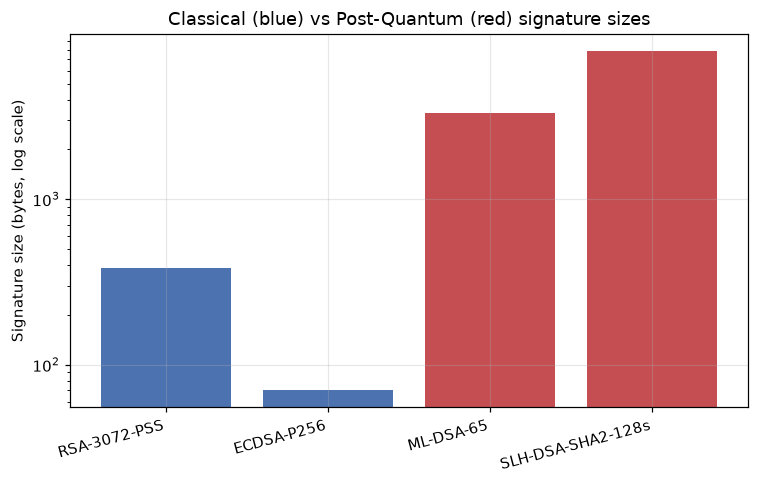

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
labels = list(sig_sizes.keys())
values = list(sig_sizes.values())
colors = ["#4C72B0", "#4C72B0", "#C44E52", "#C44E52"]
ax.bar(labels, values, color=colors)
ax.set_ylabel("Signature size (bytes, log scale)")
ax.set_yscale("log")
ax.set_title("Classical (blue) vs Post-Quantum (red) signature sizes")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "signature_sizes.png", bbox_inches="tight")
plt.show()

In [6]:
sig_bench_display = sig_bench[["algorithm", "operation", "mean_ms", "p95_ms", "p99_ms", "note"]] \
    if "note" in sig_bench.columns else sig_bench[["algorithm", "operation", "mean_ms", "p95_ms", "p99_ms"]]
sig_bench_display

,algorithm,operation,mean_ms,p95_ms,p99_ms,note
0,RSA-3072-PSS,sign,6.0351,8.0505,8.8269,NaN
1,RSA-3072-PSS,verify,0.2384,0.3967,0.4439,NaN
2,ECDSA-P256,sign,1.1513,0.1193,22.6668,NaN
3,ECDSA-P256,verify,0.2013,0.2603,0.2765,NaN
4,ML-DSA-65,sign,347.8604,864.0639,1348.6609,NaN
5,ML-DSA-65,verify,50.8330,71.3735,77.6228,NaN
6,SLH-DSA-SHA2-128s,sign,15238.1199,16268.8325,16343.8194,REDUCED_REPS_PURE_PYTHON
7,SLH-DSA-SHA2-128s,verify,13.1416,16.9207,18.4709,NaN


**ML-DSA-65's large sign-time variance** (mean 347.9ms, but ranging from 86ms to 1494ms across 30 runs) is a
**genuine mathematical property**, not measurement noise: Dilithium/ML-DSA uses Fiat-Shamir-with-aborts rejection
sampling, which by construction requires a variable, sometimes large, number of internal attempts before
producing a valid signature.

**SLH-DSA (SPHINCS+) signing took ~15 seconds per call** in this pure-Python implementation (reduced to 5
repetitions for that specific measurement, given the cost — `note: REDUCED_REPS_PURE_PYTHON` above). This
reflects both an inherent property of stateless hash-based signatures (building a large Merkle-tree
authentication structure per signature) and the overhead of a pure-Python (not native/hardware-accelerated)
implementation — this timing should **not** be generalized to an optimized native SLH-DSA implementation.

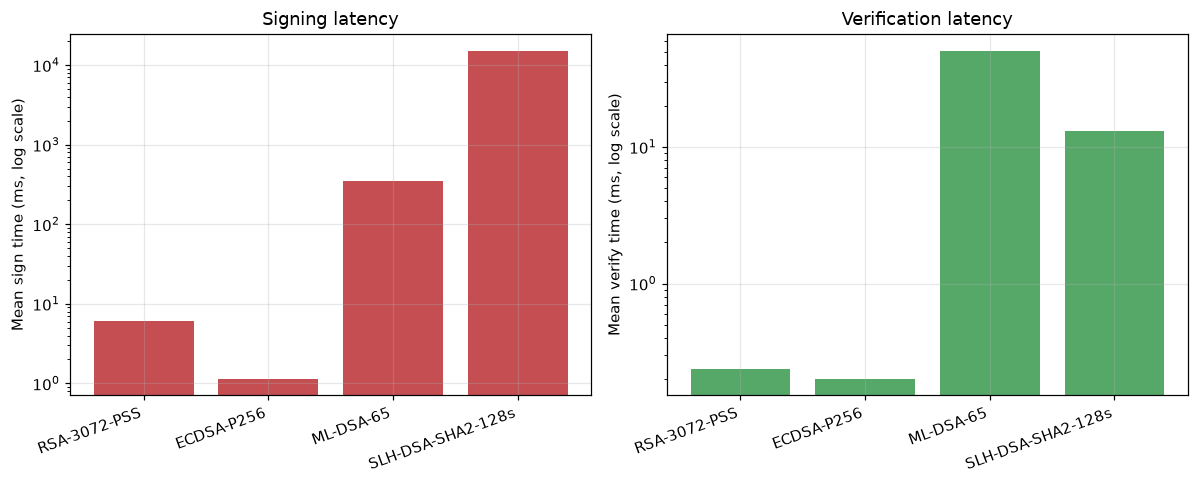

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sign_ops = sig_bench[sig_bench["operation"] == "sign"]
verify_ops = sig_bench[sig_bench["operation"] == "verify"]
axes[0].bar(sign_ops["algorithm"], sign_ops["mean_ms"], color="#C44E52")
axes[0].set_yscale("log"); axes[0].set_ylabel("Mean sign time (ms, log scale)")
axes[0].set_title("Signing latency"); plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[1].bar(verify_ops["algorithm"], verify_ops["mean_ms"], color="#55A868")
axes[1].set_yscale("log"); axes[1].set_ylabel("Mean verify time (ms, log scale)")
axes[1].set_title("Verification latency"); plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "sign_verify_latency.png", bbox_inches="tight")
plt.show()

## 20b. Cryptographic Protection Workflow

```mermaid
graph TD
    A[Transaction Payload] --> B[Security Profile Selection]
    B --> C[Key Establishment: ECDH and/or ML-KEM]
    C --> D[HKDF-SHA256 -> AES-256 key]
    D --> E[AES-256-GCM Authenticated Encryption]
    E --> F[Digital Signature: ECDSA / ML-DSA / plus SLH-DSA]
    F --> G[Protected Transaction]
    style C fill:#FCEAEA,stroke:#C44E52
```

![Layer 2 cryptographic workflow](../artifacts/figures/diagrams/layer2_crypto_workflow.png)

Note precisely: ML-KEM establishes a *key*, it does not directly encrypt the transaction payload -- AES-256-GCM
always performs the bulk symmetric encryption, per the implementation in `src/security/integration/secure_transaction.py`.

## 21. Hybrid Security Profile

The `HYBRID_MAXIMUM`/`QKD_EXPERIMENTAL` profiles combine a classical ECDH secret and a PQC ML-KEM secret via a
single HKDF-SHA256 call:

$$K = \text{HKDF-SHA256}(\text{ECDH-secret} \,\|\, \text{ML-KEM-secret}, \text{info})$$

This is a standard "concatenation combiner": security holds as long as **at least one** input secret is secure —
exactly the crypto-agility property a classical-to-PQC transition needs. `QKD_EXPERIMENTAL` additionally mixes in
BB84-simulated key material, but **always also** includes the classical+PQC hybrid secret, so a fraud-triggered
simulated-QKD step is never the *only* key material.

In [8]:
hybrid_bench = pd.read_csv(RESULTS_L2 / "hybrid_crypto_benchmarks.csv")
hybrid_bench

,algorithm,operation,n,mean_ms,median_ms,std_ms,p50_ms,p95_ms,p99_ms,min_ms,max_ms
0,ECDH-P256+ML-KEM-768,hybrid_key_establishment,30,19.8356,17.9186,6.1664,17.9186,33.4848,39.5743,14.5929,40.4249
1,ML-DSA-65+SLH-DSA-SHA2-128s,hybrid_dual_sign_ml_dsa_component_only,30,261.1112,193.6159,199.6151,193.6159,601.1205,931.1848,86.0900,1052.1905


## 24-29. Layer 1 -> Layer 2 Policy Ablation

Executed per the pre-specified `docs/protocols/LAYER2_INTEGRATION_PROTOCOL.md`. Definitions:

$$SER = \frac{N_{\text{escalated}}}{N_{\text{total}}} \qquad
FWC = \frac{N_{\text{fraud, escalated}}}{N_{\text{fraud, total}}} \qquad
BER = \frac{N_{\text{legitimate, escalated}}}{N_{\text{legitimate, total}}}$$

In [9]:
policy_ablation = pd.read_csv(RESULTS_INT / "policy_ablation.csv")
cols = [c for c in ["policy", "n", "n_fraud", "security_escalation_rate", "fraud_weighted_coverage",
                     "benign_escalation_rate"] if c in policy_ablation.columns]
policy_ablation[cols]

,policy,n,n_fraud,security_escalation_rate,fraud_weighted_coverage,benign_escalation_rate
0,A_categorical,55133,74,0.0011,0.7432,0.0001
1,B_continuous,55133,74,0.0011,0.7432,0.0001
2,C_anomaly_assisted,55133,74,0.0015,0.7432,0.0005


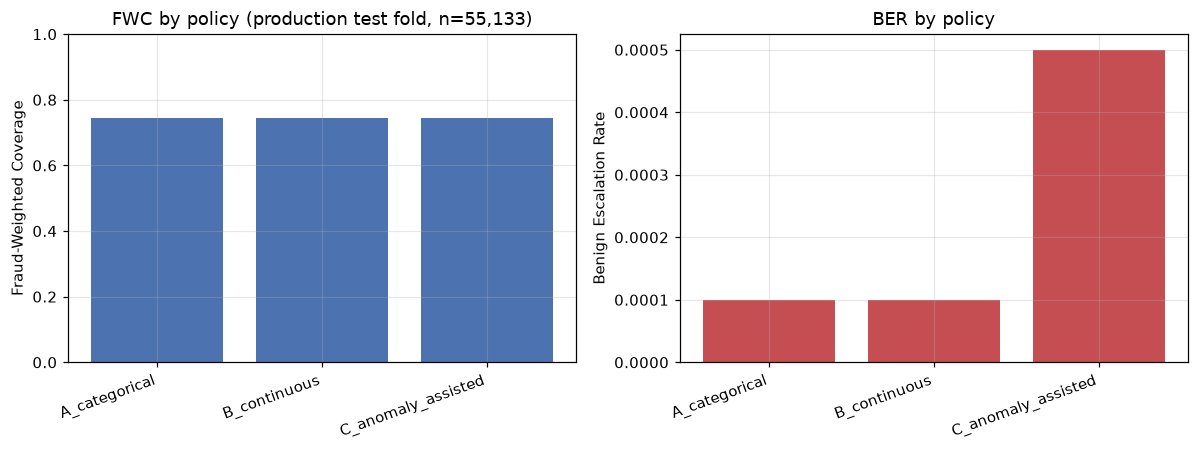

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(policy_ablation["policy"], policy_ablation["fraud_weighted_coverage"], color="#4C72B0")
axes[0].set_ylabel("Fraud-Weighted Coverage"); axes[0].set_ylim(0, 1)
axes[0].set_title("FWC by policy (production test fold, n=55,133)")
plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[1].bar(policy_ablation["policy"], policy_ablation["benign_escalation_rate"], color="#C44E52")
axes[1].set_ylabel("Benign Escalation Rate")
axes[1].set_title("BER by policy")
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "policy_ablation.png", bbox_inches="tight")
plt.show()

**Finding**: Categorical (A) and Continuous (B) routing are behaviorally **identical** on this dataset's actual
fraud-probability distribution (74.32% coverage, both) -- an honest null result. **Anomaly-assisted routing (C)
adds no additional fraud coverage but a 5x higher benign escalation rate** -- a real negative finding for this
specific escalation rule at its tested threshold.

## 30. Quantum-Assisted Routing Experiment (Policy D)

Evaluated on its own separate sample (the locked QML-M CONFIRM_VAL subset, n=250) per the pre-specified protocol
— **never numerically merged** with the A/B/C table above (different sample size, prevalence, and feature
representation). Uses the frozen, already-validated Local-Sum-observable QNN (Notebook 1, Section 20-26) and
`classical_quantum_disagreement = |p_{\text{classical}} - p_{\text{quantum}}|`.

In [11]:
quantum_aux = json.load(open(RESULTS_INT / "quantum_auxiliary_result.json"))
print(json.dumps(quantum_aux, indent=2))

{
  "fwc_B": 0.9067,
  "fwc_D": 0.92,
  "ber_B": 0.0114,
  "ber_D": 0.1829,
  "delta_fwc": 0.0133,
  "delta_ber": 0.1714,
  "n_routing_changed": 31,
  "n_routing_changed_that_were_fraud": 1,
  "svm_rbf_pr_auc": 0.967,
  "local_sum_qnn_pr_auc": 0.8663,
  "mean_disagreement": 0.2809
}


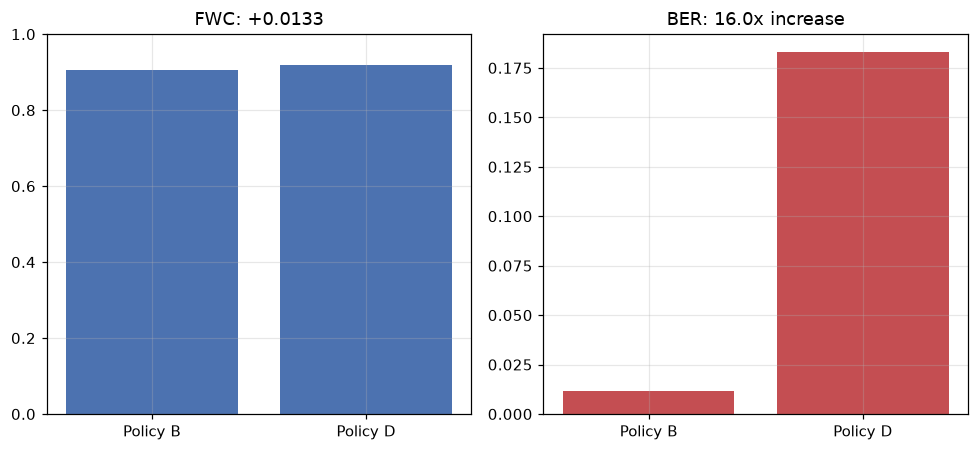


31 rows changed routing; only 1 of those were real fraud.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].bar(["Policy B", "Policy D"], [quantum_aux["fwc_B"], quantum_aux["fwc_D"]], color="#4C72B0")
axes[0].set_title(f"FWC: +{quantum_aux['delta_fwc']:.4f}"); axes[0].set_ylim(0, 1)
axes[1].bar(["Policy B", "Policy D"], [quantum_aux["ber_B"], quantum_aux["ber_D"]], color="#C44E52")
axes[1].set_title(f"BER: {quantum_aux['ber_D']/quantum_aux['ber_B']:.1f}x increase")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "quantum_auxiliary_routing.png", bbox_inches="tight")
plt.show()
print(f"\n{quantum_aux['n_routing_changed']} rows changed routing; only "
      f"{quantum_aux['n_routing_changed_that_were_fraud']} of those were real fraud.")

**QUANTUM AUXILIARY VALUE FOR LAYER 2: NOT SUPPORTED.** The classical/quantum disagreement signal increased
fraud coverage by only 1.33 percentage points (1 additional fraud caught out of 75) while increasing benign
escalation by **16x**, dramatically failing the protocol's pre-specified cost budget (BER within 1.5x of the
categorical baseline). This mirrors Layer 1's own finding that the Local-Sum QNN, despite being a real,
statistically validated architecture-level improvement over the Global-observable QNN, does not translate into
useful predictive information at the system level.

## 31-35. BB84 Theory, Simulation, and Results

Bases:

$$|0\rangle,\ |1\rangle \text{ (computational)} \qquad
|+\rangle = \frac{|0\rangle+|1\rangle}{\sqrt2},\ |-\rangle = \frac{|0\rangle-|1\rangle}{\sqrt2} \text{ (Hadamard)}$$

$$QBER = \frac{N_{\text{error}}}{N_{\text{sifted}}}$$

**This is a classical software simulation of BB84's information-theoretic structure** (`src/security/qkd/bb84.py`)
— no physical quantum channel, no hardware, no claim of physical QKD security.

```mermaid
graph TD
    A[Alice: random bits + random bases] --> B[State preparation]
    B --> C[Quantum channel - optional noise]
    C --> D[Bob: random bases, measures]
    D --> E[Public basis comparison]
    E --> F[Sifted key]
    F --> G[QBER estimate -> accept/reject]
    style G fill:#FCEAEA,stroke:#C44E52
```

![BB84 protocol](../artifacts/figures/diagrams/bb84_protocol_diagram.png)

**Intercept-resend eavesdropper**: Eve measures in a randomly chosen basis and resends a freshly prepared qubit.
When her basis does not match Alice's, her measurement (and resend) is uniformly random, introducing a
detectable bit error with probability approximately 25% on those qubits -- this is the mechanism the simulation
reproduces from real random measurements, not a hardcoded value.

![BB84 intercept-resend](../artifacts/figures/diagrams/bb84_intercept_resend_diagram.png)

In [13]:
bb84_summary = pd.read_csv(RESULTS_L2 / "bb84_summary.csv")
bb84_summary

,condition,n_trials,mean_qber,std_qber,mean_sifted_length,sifted_ratio,detection_rate,key_acceptance_rate
0,clean,30,0.0000,0.0000,1005.5,0.5027,NaN,1.0
1,noise_1pct,30,0.0089,0.0052,1005.5,0.5027,NaN,1.0
2,noise_5pct,30,0.0479,0.0091,1005.5,0.5027,NaN,1.0
3,noise_10pct,30,0.0947,0.0192,1005.5,0.5027,NaN,0.8
4,eve_intercept_resend,30,0.2394,0.0237,1004.0,0.5020,1.0,0.0
5,eve_and_noise_2pct,30,0.2642,0.0192,1004.0,0.5020,1.0,0.0


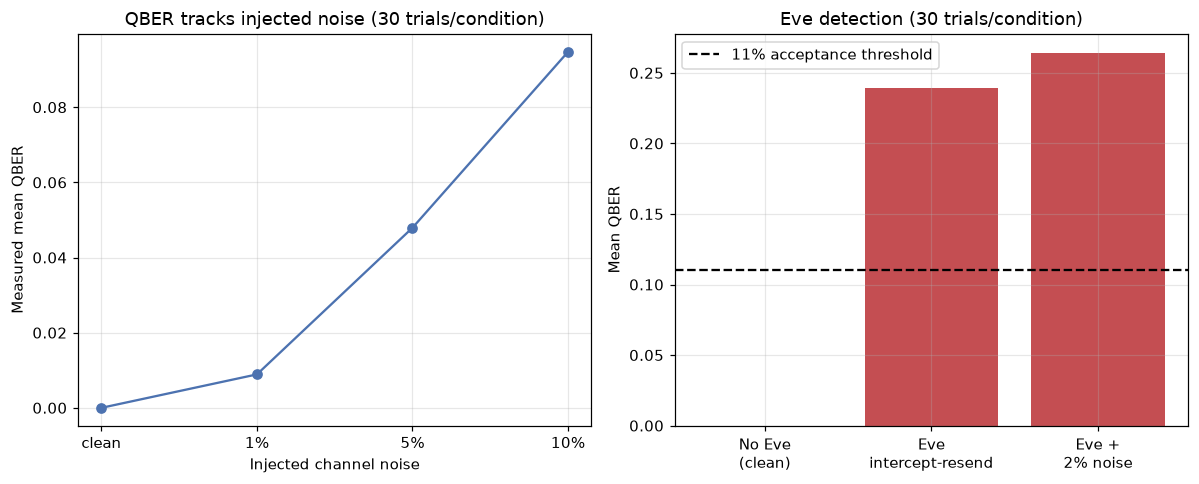

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
noise_order = ["clean", "noise_1pct", "noise_5pct", "noise_10pct"]
noise_conditions = bb84_summary.set_index("condition").loc[noise_order].reset_index()
axes[0].plot(["clean", "1%", "5%", "10%"], noise_conditions["mean_qber"], marker="o", color="#4C72B0")
axes[0].set_xlabel("Injected channel noise"); axes[0].set_ylabel("Measured mean QBER")
axes[0].set_title("QBER tracks injected noise (30 trials/condition)")

eve_conditions = bb84_summary[bb84_summary["condition"].str.contains("eve")]
labels = ["No Eve\n(clean)", "Eve\nintercept-resend", "Eve +\n2% noise"]
values = [bb84_summary[bb84_summary["condition"]=="clean"]["mean_qber"].iloc[0]] + list(eve_conditions["mean_qber"])
axes[1].bar(labels, values, color=["#55A868", "#C44E52", "#C44E52"])
axes[1].axhline(0.11, color="black", linestyle="--", label="11% acceptance threshold")
axes[1].set_ylabel("Mean QBER"); axes[1].set_title("Eve detection (30 trials/condition)")
axes[1].legend()
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_qber.png", bbox_inches="tight")
plt.show()

**Result, with exact experimental conditions stated** (30 trials per condition, raw key length 2000 bits,
`scripts/security/run_bb84_and_e2e_benchmarks.py`): QBER tracks injected channel noise almost linearly (1%->0.89%,
5%->4.79%, 10%->9.47%). The intercept-resend eavesdropper was detected in **30/30 trials** at these specific
settings (measured QBER ~24-26%, close to the textbook ~25% expectation for this attack) — this is not claimed as
a universal 100% detection guarantee, only as the observed rate under these exact conditions. At 10% channel
noise (near the 11% acceptance threshold), 20% of trials were rejected due to natural finite-sample QBER
estimation variance — an expected statistical effect, not a simulation defect.

## 35b. Implementation Backend as an Experimental Variable

Two follow-up experiments turn the implementation limitations above into explicit research questions rather than
leaving them as unquantified caveats: **(i)** does a native PQC backend change the measured cost picture, and
**(ii)** does an independent, circuit-level BB84 implementation reproduce the protocol-level simulator's results?

### (i) Native PQC backend attempt

`liboqs-python` (a wrapper around the native `liboqs` C library) was installed via `pip install liboqs-python`.
Importing it triggers an automatic native-library build via `cmake`, which failed immediately:

In [15]:
# Reproduces the exact failure observed when attempting the native PQC backend:
#   import oqs
#   -> FileNotFoundError: [WinError 2] The system cannot find the file specified
# because no CMake/MSVC C/C++ toolchain is present on PATH in this Windows environment.
import shutil
print("cmake on PATH:", shutil.which("cmake"))
print("cl.exe (MSVC) on PATH:", shutil.which("cl"))

cmake on PATH: None
cl.exe (MSVC) on PATH: None


**Result: NATIVE PQC BACKEND UNAVAILABLE IN CURRENT ENVIRONMENT.** No C/C++ toolchain (CMake, MSVC) is available
to build native `liboqs` in this sandboxed Windows environment, and no other cryptographic package was
substituted merely for having a similar name (per the pre-specified fallback rule for this experiment). This is a
disclosed environment limitation, not evidence about the algorithms themselves: the pure-Python reference
implementations used throughout this notebook remain correct (verified via genuine round-trip and
tamper-rejection tests) but their latency — including the ~15-second SLH-DSA signing time reported in Section 14
— should be read as **reference-implementation cost**, not as a general statement about SLH-DSA's practicality
on optimized native code. See `docs/research/layer2/LAYER2_LIMITATIONS.md` for the full record of this attempt.

### (ii) Qiskit circuit-level BB84 cross-validation

An independent, circuit-level BB84 implementation was built using Qiskit + Qiskit Aer
(`src/security/qkd/bb84_qiskit.py`), which prepares and measures explicit single-qubit states rather than
sampling protocol-level probabilities directly:

$$\text{bit=0, Z} \to |0\rangle \text{ (no gate)} \qquad \text{bit=1, Z} \to |1\rangle \text{ (X gate)}$$
$$\text{bit=0, X} \to |+\rangle \text{ (H gate)} \qquad \text{bit=1, X} \to |-\rangle \text{ (X then H)}$$

Measurement in the X basis applies an H gate before a computational-basis measurement.

In [16]:
from qiskit import QuantumCircuit
import sys
sys.path.insert(0, str(ROOT / "src"))
from security.qkd.bb84_qiskit import prepare_circuit, measure_circuit

fig = measure_circuit(prepare_circuit(1, "Z"), "Z").draw("mpl")
fig.suptitle("Representative Alice -> Bob circuit (bit=1, Z basis, matching bases)")
fig.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_circuit_full_representative.png", bbox_inches="tight")
plt.show()

In [17]:
fig = measure_circuit(prepare_circuit(1, "Z"), "X").draw("mpl")
fig.suptitle("Eve intercept: measures Alice's Z-basis |1> state in the wrong (X) basis")
fig.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_circuit_eve_intercept_representative.png", bbox_inches="tight")
plt.show()

The circuit implementation was run under the same six conditions as the protocol-level simulator (30 trials per
condition, `scripts/security/run_bb84_qiskit_benchmarks.py`), using a reduced raw-bit count per trial (200 vs.
2000) to bound per-qubit circuit-simulation overhead -- this reduction is disclosed, not hidden.

In [18]:
bb84_cross = pd.read_csv(RESULTS_L2 / "bb84_cross_implementation_comparison.csv")
bb84_cross

,condition,protocol_mean_qber,qiskit_mean_qber,abs_diff,protocol_detection_rate,qiskit_detection_rate
0,clean,0.0000,0.0000,0.0000,NaN,NaN
1,noise_1pct,0.0089,0.0134,0.0045,NaN,NaN
2,noise_5pct,0.0479,0.0503,0.0024,NaN,NaN
3,noise_10pct,0.0947,0.1009,0.0062,NaN,NaN
4,eve_intercept_resend,0.2394,0.2447,0.0053,1.0,1.0
5,eve_and_noise_2pct,0.2642,0.2647,0.0005,1.0,1.0


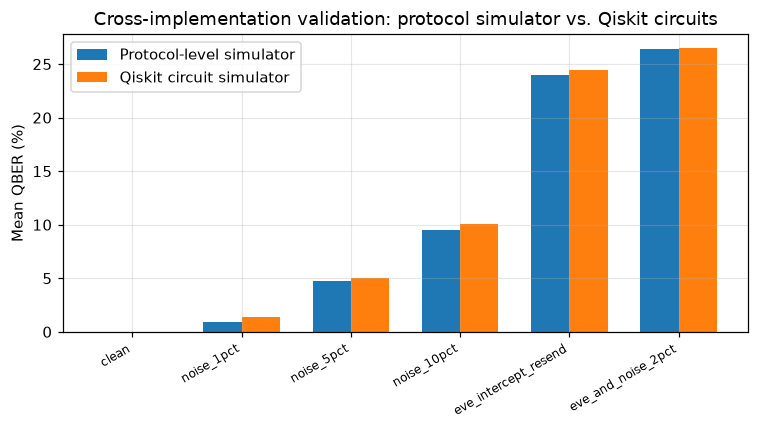

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(bb84_cross))
width = 0.35
ax.bar([i - width/2 for i in x], bb84_cross["protocol_mean_qber"].astype(float) * 100, width, label="Protocol-level simulator")
ax.bar([i + width/2 for i in x], bb84_cross["qiskit_mean_qber"].astype(float) * 100, width, label="Qiskit circuit simulator")
ax.set_xticks(list(x)); ax.set_xticklabels(bb84_cross["condition"], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("Mean QBER (%)")
ax.set_title("Cross-implementation validation: protocol simulator vs. Qiskit circuits")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_cross_implementation_comparison.png", bbox_inches="tight")
plt.show()

**Result: the two independent implementations agree closely** across all six conditions (largest absolute
difference 0.0062, on 200-bit vs. 2000-bit samples per trial) -- see the table above. The Qiskit circuit
implementation also detected the intercept-resend eavesdropper in 30/30 trials at the same 0.11 QBER threshold.
This is cross-implementation validation that the protocol-level simulator's sifting and QBER-estimation logic
correctly reproduces the behavior of explicit per-qubit state preparation and measurement circuits.

**This does not change the software-simulation status of BB84 in this project.** Running these circuits on
Qiskit Aer's classical simulator (or, hypothetically, on real IBM Quantum hardware) still transmits no physical
photon and exercises no physical no-cloning property. **BB84 in this project remains, in every implementation, a
software simulation** -- the improvement is circuit-level validation, not physical quantum key distribution.

## 36-37. End-to-End Secure Transaction Pipeline and Latency

In [20]:
e2e = pd.read_csv(RESULTS_L2 / "end_to_end_benchmarks.csv")
cols = [c for c in ["case", "fraud_probability", "selected_profile", "total_security_ms"] if c in e2e.columns]
e2e[cols]

,case,fraud_probability,selected_profile,total_security_ms
0,very_low_risk,0.02,BASELINE,23.9150
1,borderline_low_medium,0.29,BASELINE,1.2597
2,medium_risk,0.50,PQC_ENHANCED,52.6575
3,borderline_medium_high,0.69,PQC_ENHANCED,45.3424
4,high_risk,0.90,HYBRID_MAXIMUM,6306.7178


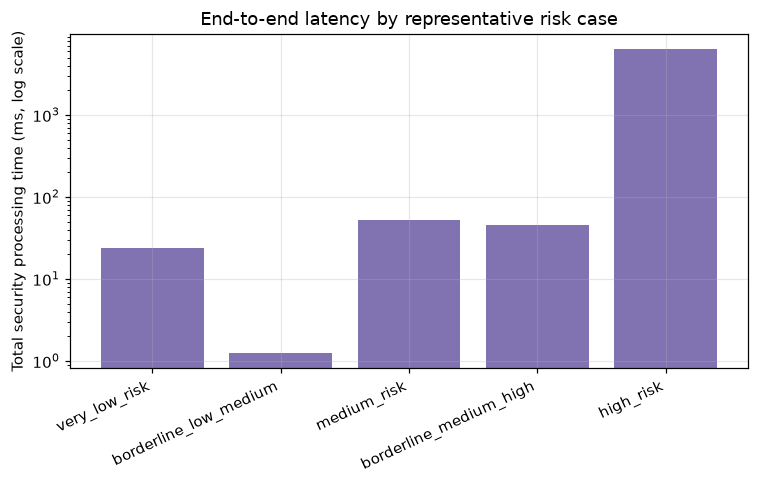


BASELINE/PQC_ENHANCED add tens of ms (plausible for real-time processing).
HYBRID_MAXIMUM adds seconds, dominated by SLH-DSA signing -- a real, disclosed limitation
of this pure-Python implementation, not minimized here or in docs/research/layer2/LAYER2_RESULTS.md.


In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(e2e["case"], e2e["total_security_ms"], color="#8172B2")
ax.set_yscale("log")
ax.set_ylabel("Total security processing time (ms, log scale)")
ax.set_title("End-to-end latency by representative risk case")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "end_to_end_latency.png", bbox_inches="tight")
plt.show()
print("\nBASELINE/PQC_ENHANCED add tens of ms (plausible for real-time processing).")
print("HYBRID_MAXIMUM adds seconds, dominated by SLH-DSA signing -- a real, disclosed limitation")
print("of this pure-Python implementation, not minimized here or in docs/research/layer2/LAYER2_RESULTS.md.")

## 35c. Optimized PQC Backend (pqcrypto) vs Reference Python Implementation

**Research question.** How strongly does the *software implementation* change measured PQC latency, and which costs
remain once the implementation is compiled? Native `liboqs` could not be built in this environment (no CMake/MSVC;
Section 35b), so the optimized backend is the compiled `pqcrypto` package (ML-KEM, ML-DSA, SLH-DSA). Reference =
`kyber-py`, `dilithium-py`, `slh-dsa` (pure Python). All timings use `time.perf_counter_ns`; warm-up runs and
imports are excluded; repetition counts `n` differ by backend (slow reference SLH-DSA uses n = 3) and are reported.

$$S = \frac{T_{\mathrm{reference}}}{T_{\mathrm{optimized}}},\qquad R = \frac{T_{\mathrm{reference}}-T_{\mathrm{optimized}}}{T_{\mathrm{reference}}}\times 100\%$$

Speedup is an **implementation-backend** comparison, not evidence of a cryptographic advantage; both backends
produce identical key, ciphertext and signature sizes.

In [22]:
from IPython.display import Image, display
pqc_sum = pd.read_csv(RESULTS_L2 / "pqcrypto_summary.csv")
pqc_cmp = pd.read_csv(RESULTS_L2 / "pqc_backend_comparison.csv")
pqc_meta = json.load(open(RESULTS_L2 / "pqc_benchmark_meta.json"))
print("pqcrypto", pqc_meta["backends"]["pqcrypto"], "| reference libs", pqc_meta["backends"]["reference_python"]["libraries"])
print("liboqs:", pqc_meta["liboqs"])
pqc_cmp[["algorithm","operation","n_reference","n_optimized","reference_median_ms","optimized_median_ms","speedup","reduction_pct"]].round(3)

pqcrypto {'available': True, 'version': '1.0.0'} | reference libs {'kyber-py': '1.2.0', 'dilithium-py': '1.4.0', 'slh-dsa': '0.2.5'}
liboqs: python wrapper installed (liboqs-python 0.16.0.1); native library build failed (no CMake/MSVC); no liboqs measurements


,algorithm,operation,n_reference,n_optimized,reference_median_ms,optimized_median_ms,speedup,reduction_pct
0,ML-DSA-44,keygen,30,200,7.170,0.137,52.434,98.093
1,ML-DSA-44,sign,30,200,25.127,6.956,3.612,72.317
2,ML-DSA-44,verify,30,200,8.124,0.140,58.239,98.283
3,ML-DSA-65,keygen,30,200,11.502,0.237,48.492,97.938
4,ML-DSA-65,sign,30,200,45.494,9.455,4.812,79.218
5,ML-DSA-65,verify,30,200,12.652,0.220,57.563,98.263
6,ML-DSA-87,keygen,30,200,17.943,0.357,50.287,98.011
7,ML-DSA-87,sign,30,200,72.622,13.302,5.460,81.684
8,ML-DSA-87,verify,30,200,20.290,0.357,56.835,98.241
9,ML-KEM-1024,decaps,30,200,9.731,0.157,61.823,98.382


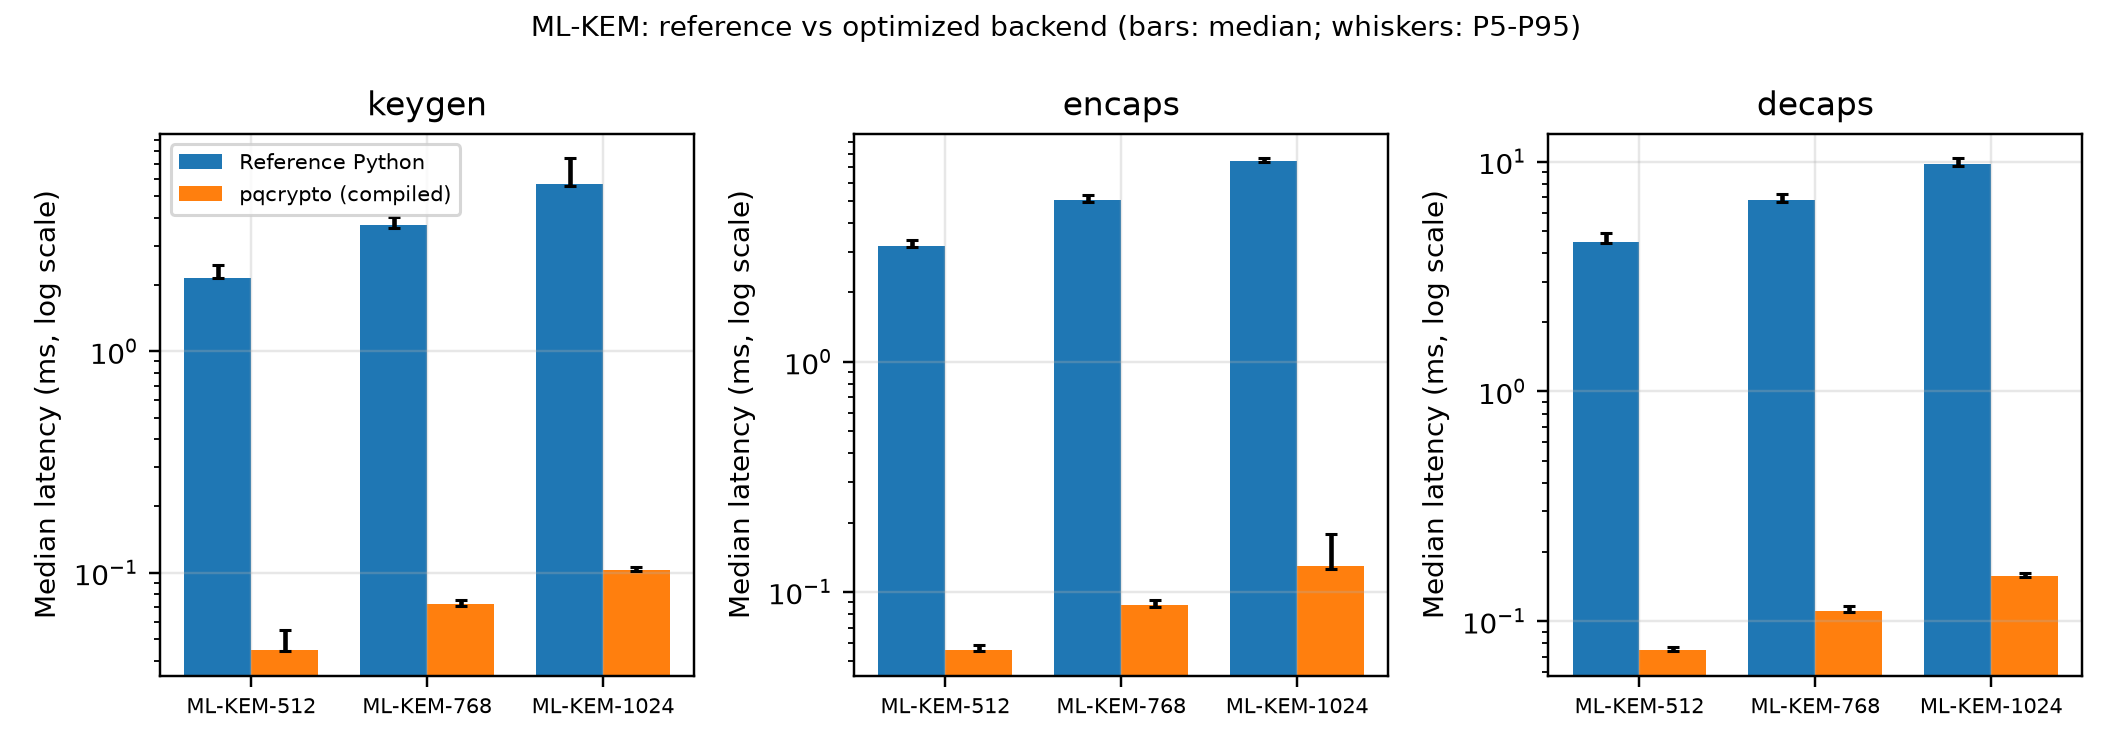

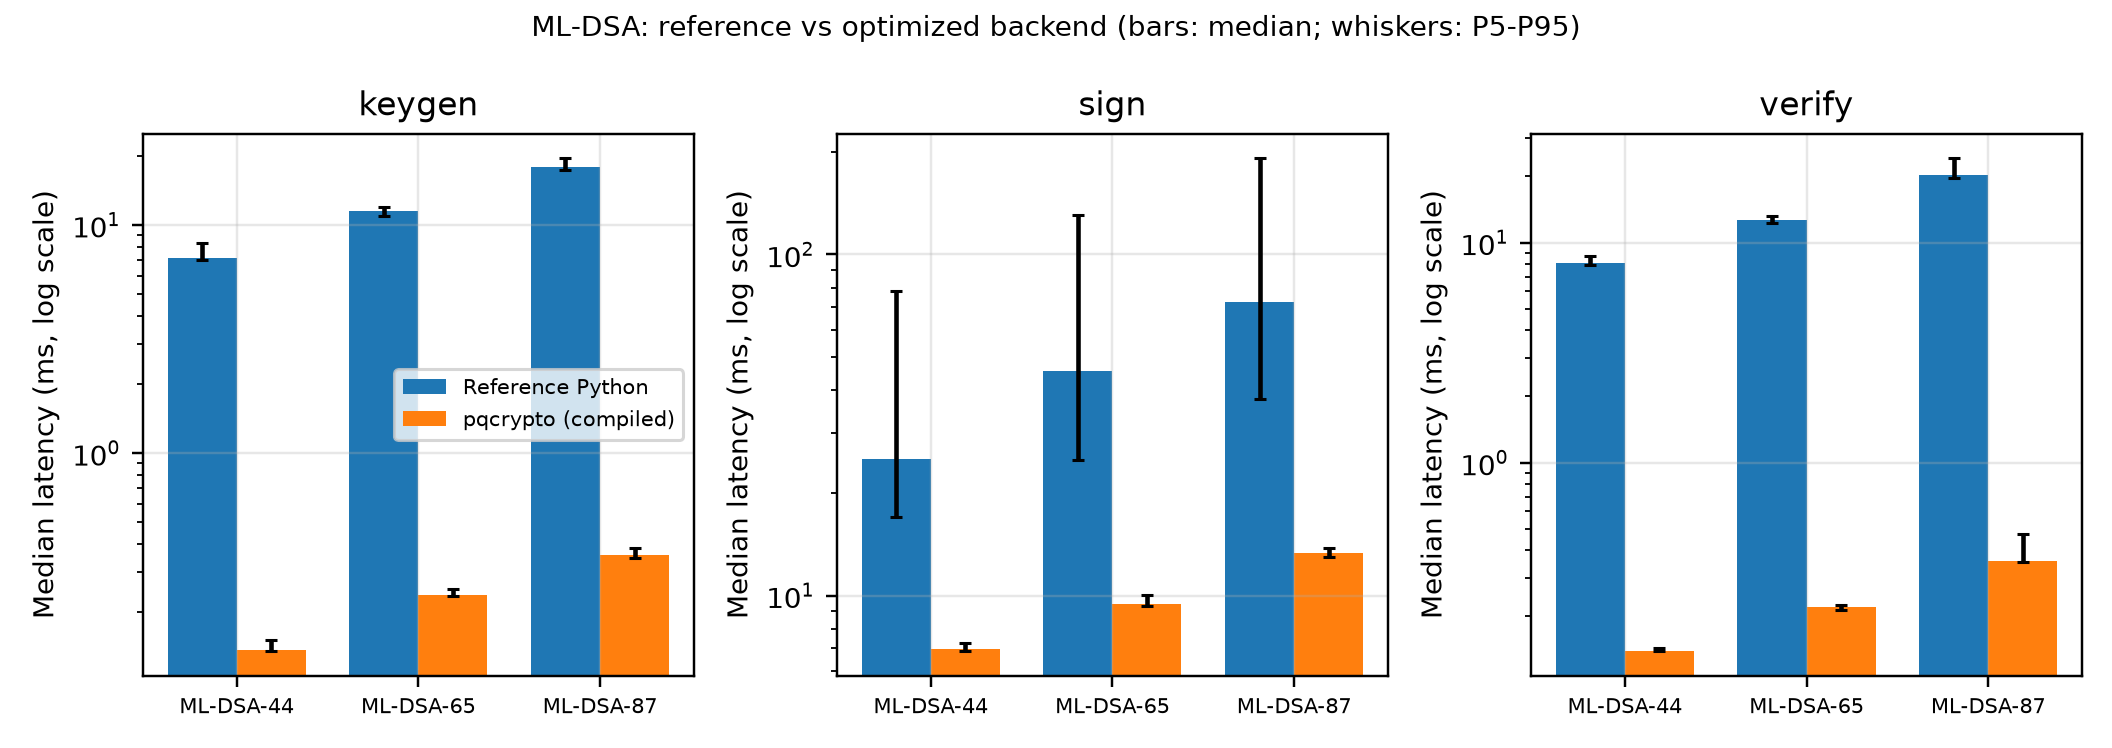

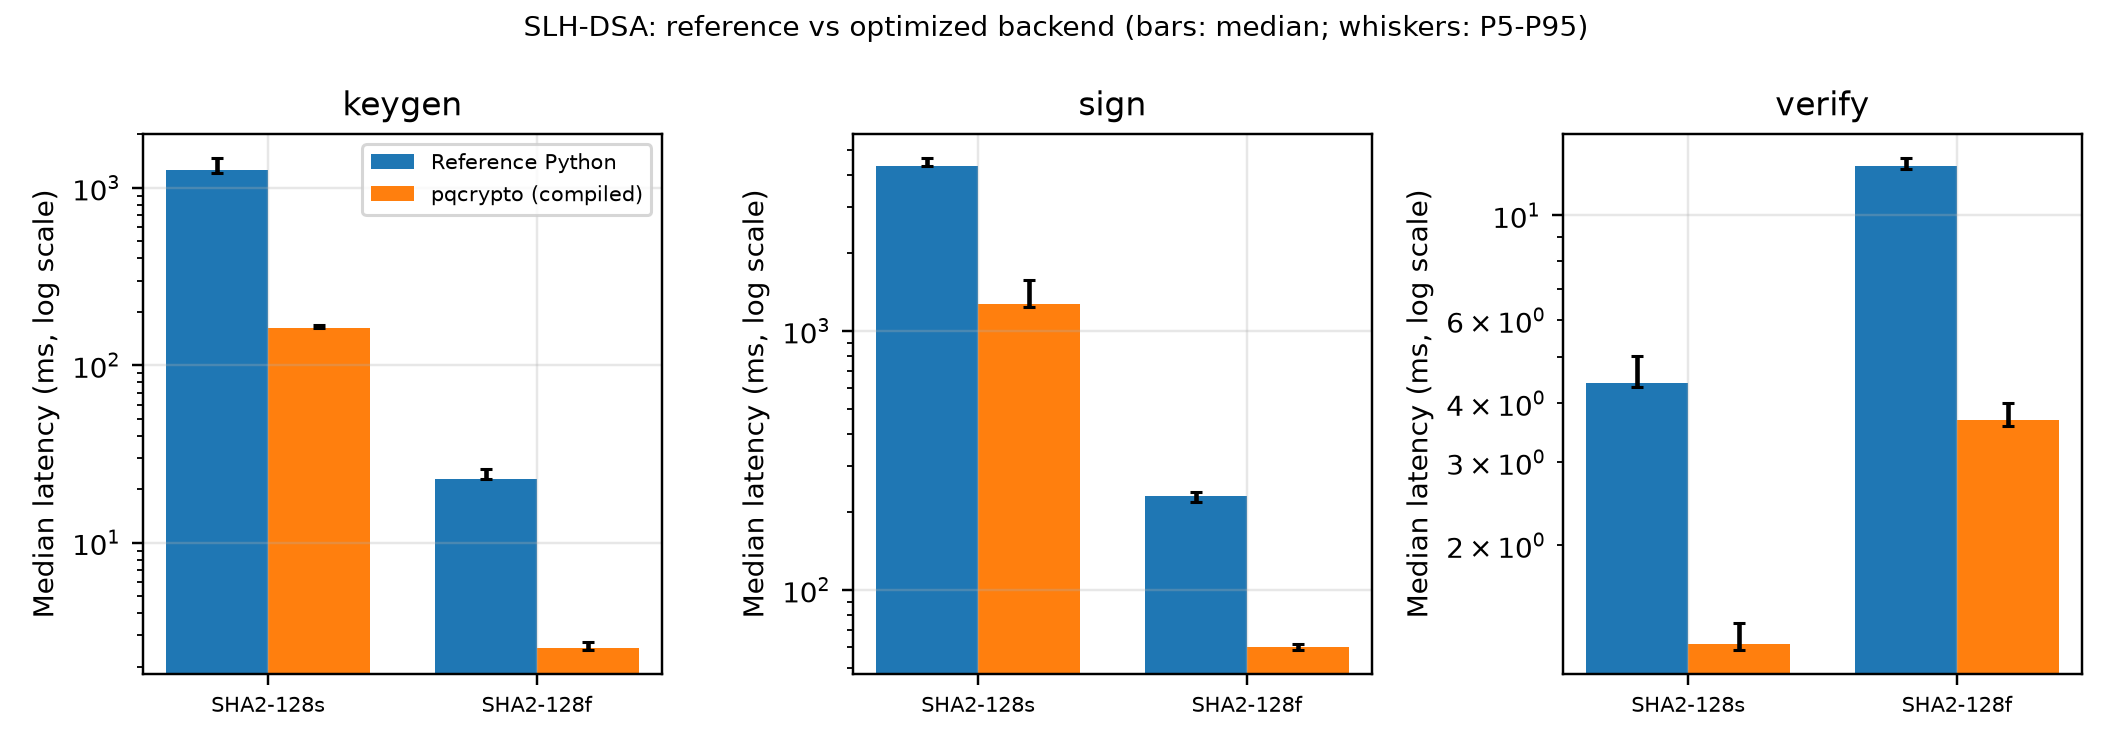

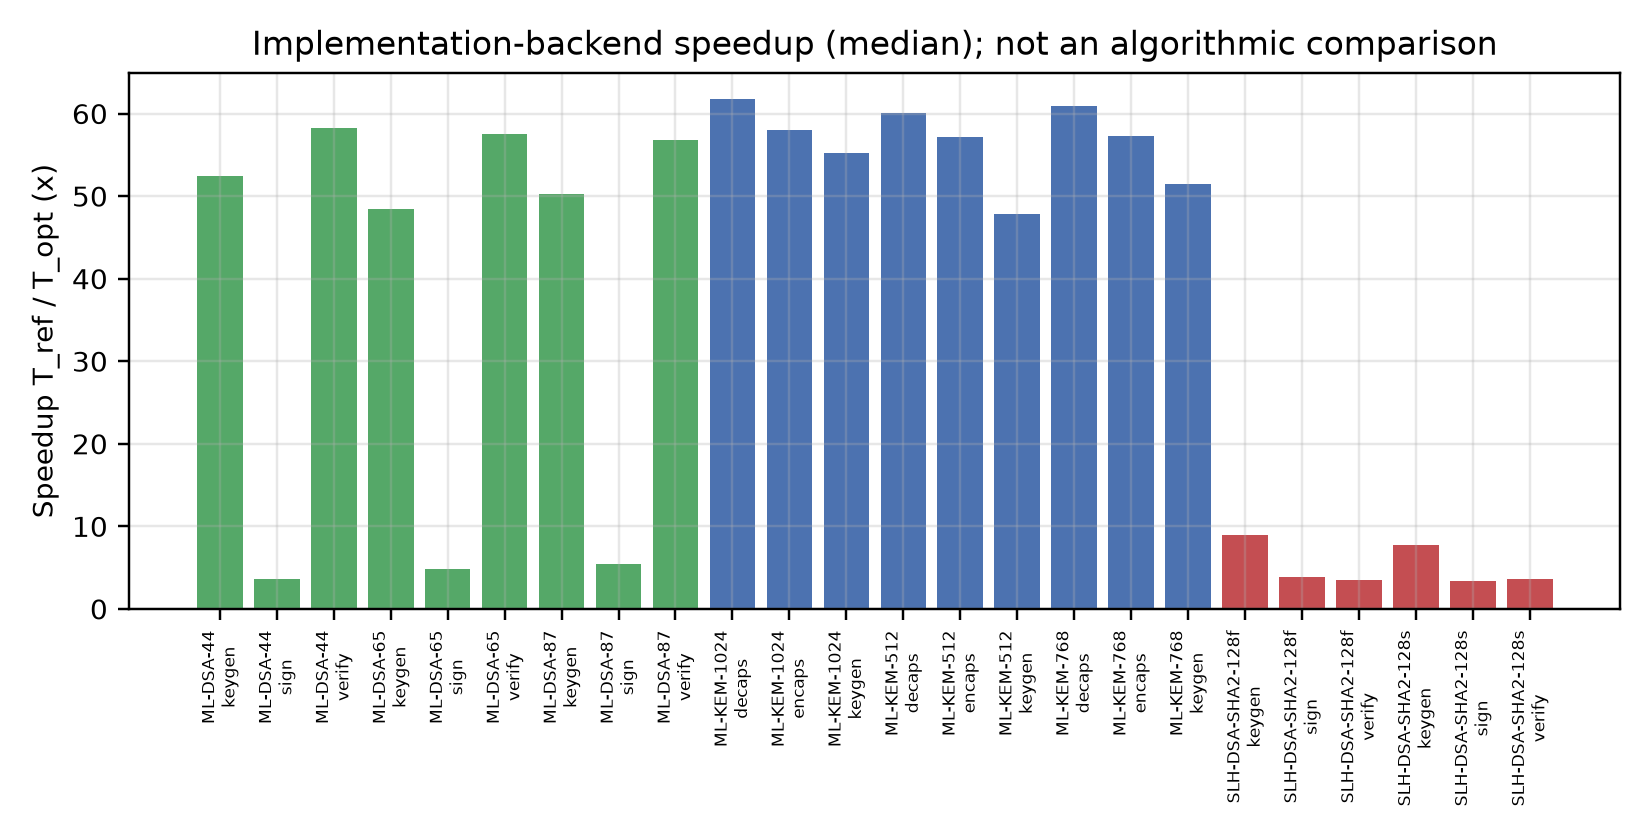

In [23]:
for f in ["pqc_ref_vs_opt_mlkem.png", "pqc_ref_vs_opt_mldsa.png", "pqc_ref_vs_opt_slhdsa.png", "pqc_backend_speedup.png"]:
    display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / f)))

### SLH-DSA implementation-cost investigation

The earlier benchmark (Section 14) reported about 15 s per SLH-DSA-SHA2-128s signature (reference Python, n = 5).
That result is **preserved**, not overwritten. The controlled re-measurement below uses the same message for both
backends in one session.

In [24]:
r = pqc_cmp[(pqc_cmp.algorithm=="SLH-DSA-SHA2-128s") & (pqc_cmp.operation=="sign")].iloc[0]
print(f"This session  reference median: {r.reference_median_ms/1000:.2f} s (n={int(r.n_reference)})")
print(f"This session  pqcrypto  median: {r.optimized_median_ms/1000:.2f} s (n={int(r.n_optimized)})  -> speedup {r.speedup:.2f}x, reduction {r.reduction_pct:.1f}%")
ml = pqc_cmp[(pqc_cmp.algorithm=="ML-DSA-65") & (pqc_cmp.operation=="sign")].iloc[0]
print(f"ML-DSA-65 sign (pqcrypto) median {ml.optimized_median_ms:.2f} ms -> SLH-DSA-128s is {r.optimized_median_ms/ml.optimized_median_ms:.0f}x slower even when compiled")
old = pd.read_csv(RESULTS_L2 / "signature_benchmarks.csv")
print(old.head(0).columns.tolist())
old[old.astype(str).apply(lambda c: c.str.contains("SLH", case=False)).any(axis=1)].round(2)

This session  reference median: 4.33 s (n=3)
This session  pqcrypto  median: 1.27 s (n=30)  -> speedup 3.41x, reduction 70.7%
ML-DSA-65 sign (pqcrypto) median 9.45 ms -> SLH-DSA-128s is 134x slower even when compiled
['algorithm', 'operation', 'max_ms', 'mean_ms', 'median_ms', 'min_ms', 'n', 'note', 'p50_ms', 'p95_ms', 'p99_ms', 'std_ms']


,algorithm,operation,max_ms,mean_ms,median_ms,min_ms,n,note,p50_ms,p95_ms,p99_ms,std_ms
6,SLH-DSA-SHA2-128s,sign,16362.57,15238.12,15585.29,13980.39,5,REDUCED_REPS_PURE_PYTHON,15585.29,16268.83,16343.82,911.39
7,SLH-DSA-SHA2-128s,verify,18.82,13.14,12.42,11.14,30,NaN,12.42,16.92,18.47,1.84


**Interpretation (from the measurements above).** Compiling SLH-DSA-SHA2-128s reduces the median signing time by
only a factor of about three to four; the compiled signature still takes on the order of a second, roughly two orders
of magnitude above compiled ML-DSA-65. The large SLH-DSA signing cost is therefore **mostly a property of the
parameter set** (hash-based, "small" variant), not only of the pure-Python reference. The fast variant
(SLH-DSA-SHA2-128f) signs much faster at the price of a larger signature (17,088 vs 7,856 bytes). The earlier
~15 s figure is reference-implementation behaviour under that session's conditions; this session's controlled
reference median is lower, so neither number is an implementation-independent cost. By contrast ML-KEM and ML-DSA key
generation, encapsulation, decapsulation and verification are roughly 50-60x faster compiled (strongly
implementation-dependent), while ML-DSA signing (rejection sampling) improves only about 3.6-5.5x.

## 35d. Classical vs Post-Quantum Comparison (by cryptographic role)

Only functionally comparable primitives are compared: key establishment (ECDH-P256 / RSA-3072 key wrap vs ML-KEM)
and digital signatures (ECDSA-P256 / RSA-3072-PSS vs ML-DSA / SLH-DSA). **AES-256-GCM is not compared with ML-KEM
or ML-DSA**: it provides bulk symmetric encryption in every configuration.

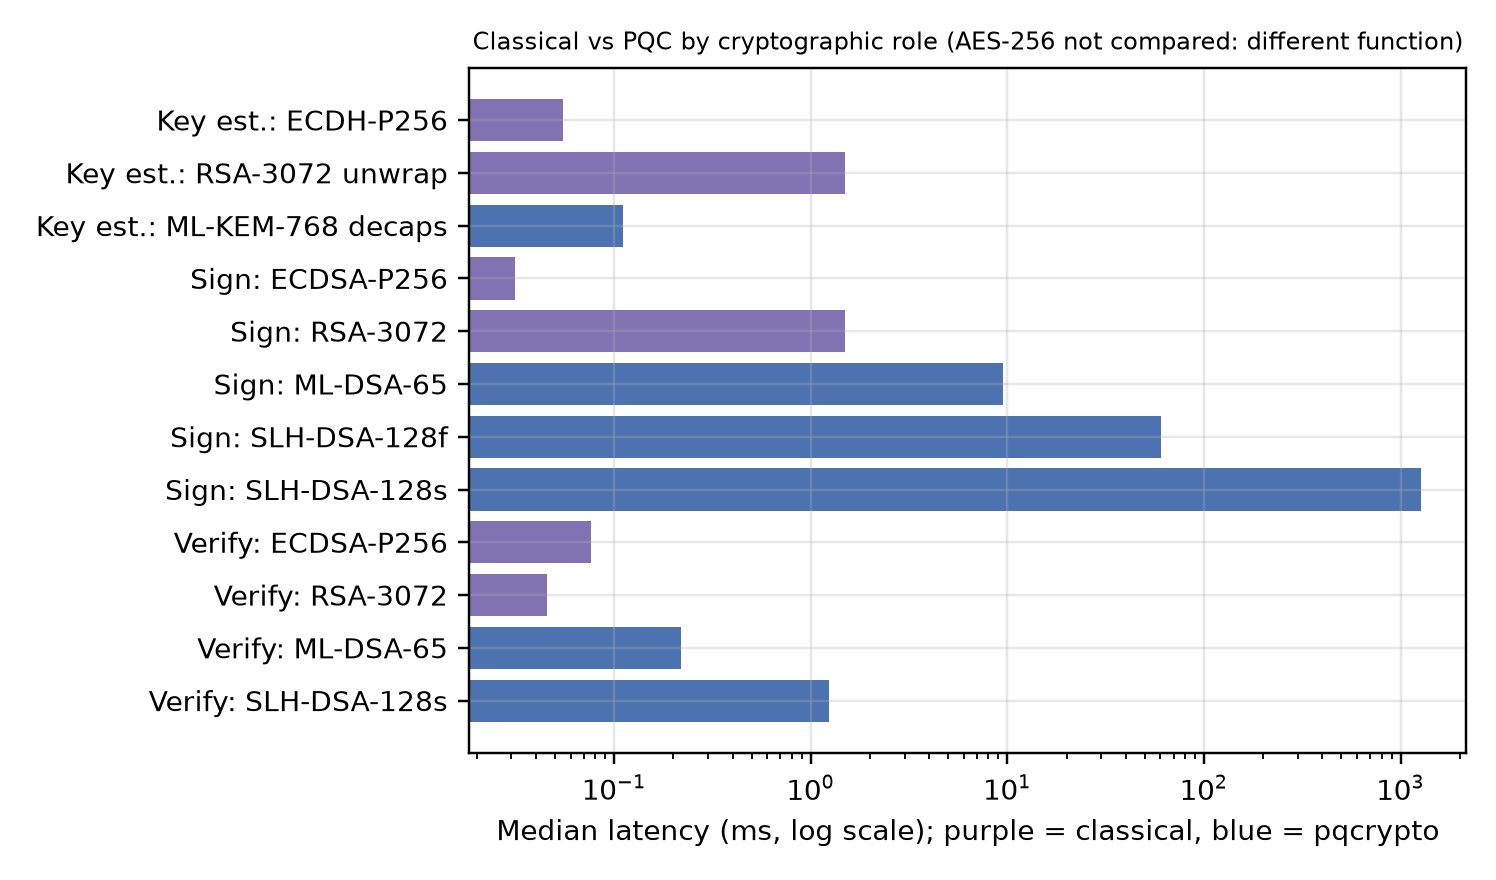

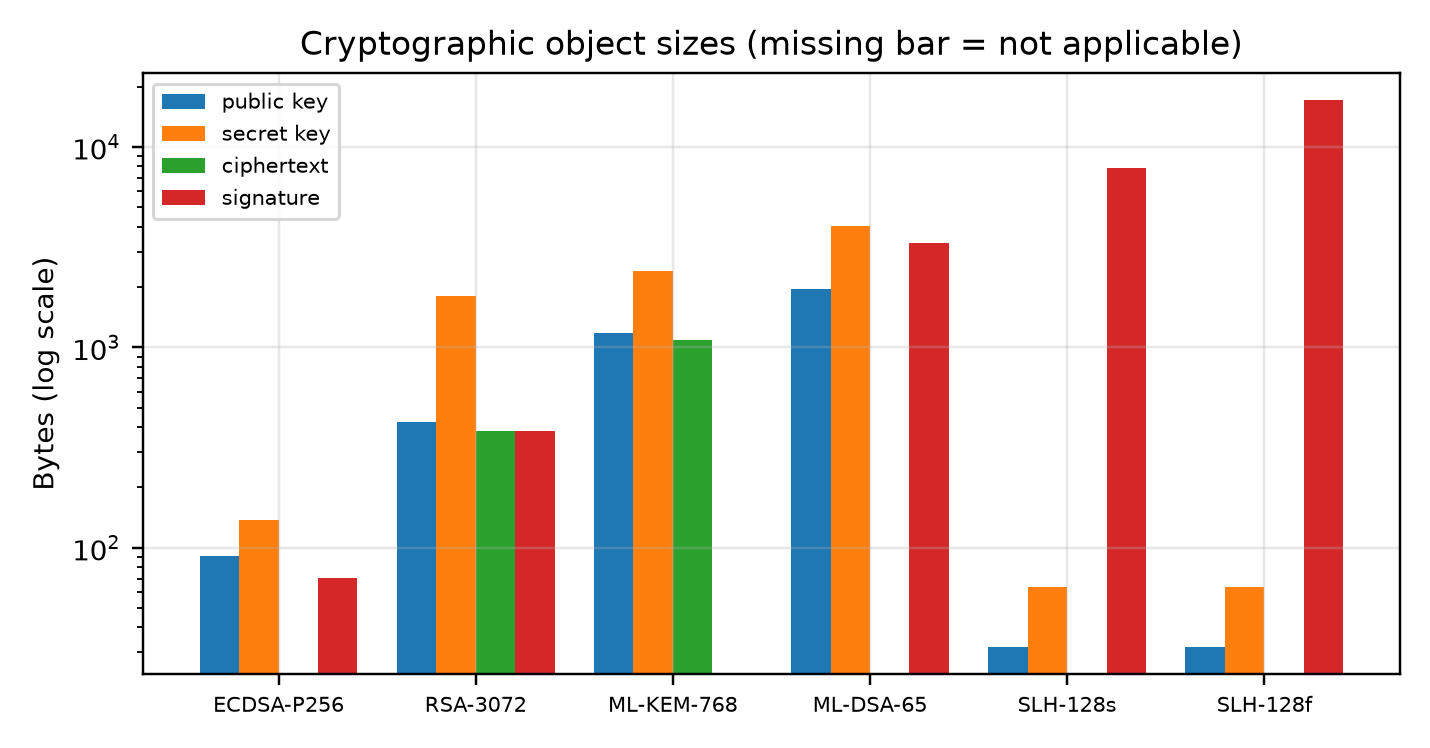

,algorithm,size_public_key,size_secret_key,size_ciphertext,size_signature
0,ECDH-P256,65,32,-,-
2,ECDSA-P256,91,138,-,71.0
4,RSA-3072,422,1795,384.0,384.0
9,ML-DSA-44,1312,2560,-,2420.0
12,ML-DSA-65,1952,4032,-,3309.0
15,ML-DSA-87,2592,4896,-,4627.0
18,ML-KEM-1024,1568,3168,1568.0,-
22,ML-KEM-512,800,1632,768.0,-
26,ML-KEM-768,1184,2400,1088.0,-
30,SLH-DSA-SHA2-128f,32,64,-,17088.0


In [25]:
display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / "classical_vs_pqc_latency.png")))
display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / "crypto_object_sizes.png")))
sz = pqc_sum[(pqc_sum.backend.isin(["classical","pqcrypto"]))].drop_duplicates("algorithm")
sz[["algorithm","size_public_key","size_secret_key","size_ciphertext","size_signature"]].fillna("-")

## 35e. End-to-End Banking Transaction Protection

Pipeline: canonical JSON serialization and SHA-256, digital signature, session-key establishment (HKDF-SHA256),
AES-256-GCM encryption, in-memory "transmission" (no network latency), decryption, signature verification. Long-term
public keys are assumed pre-distributed; per-message KEM ciphertext / ephemeral key and signature bytes count toward
the secured payload. Configuration D (hybrid) = ECDH-P256 + ML-KEM-768 secrets combined by HKDF with ECDSA + ML-DSA-65
dual signatures. Absolute latency is the primary metric.

,config,n,median_ms,p95_ms,mean_ms,plaintext_bytes,secured_bytes,payload_expansion
7,A_classical_ECDH+ECDSA,200,0.302,0.568,0.349,312,475,1.522
16,B_reference_ML-KEM-768+ML-DSA-65,30,72.827,140.549,87.519,312,4737,15.183
25,C_optimized_ML-KEM-768+ML-DSA-65,200,10.155,11.021,10.304,312,4737,15.183
34,D_hybrid_optimized_ECDH+ML-KEM-768_ECDSA+ML-DS...,200,10.534,10.990,10.566,312,4873,15.619
43,B2_reference_ML-KEM-768+SLH-DSA-128s,3,3631.691,3661.073,3628.274,312,9284,29.756
52,C2_optimized_ML-KEM-768+SLH-DSA-128s,20,1252.818,1268.356,1253.926,312,9284,29.756


config,A_classical_ECDH+ECDSA,B2_reference_ML-KEM-768+SLH-DSA-128s,B_reference_ML-KEM-768+ML-DSA-65,C2_optimized_ML-KEM-768+SLH-DSA-128s,C_optimized_ML-KEM-768+ML-DSA-65,D_hybrid_optimized_ECDH+ML-KEM-768_ECDSA+ML-DSA-65
stage,,,,,,
aes_decrypt,0.0048,0.0142,0.0083,0.0065,0.0054,0.0061
aes_encrypt,0.0063,0.0193,0.0170,0.0180,0.0081,0.0090
crypto_total,0.2846,3631.6517,72.7916,1252.7800,10.1274,10.4996
key_establish_receiver,0.0613,7.9979,6.6896,0.1324,0.1295,0.1880
key_establish_sender,0.0961,5.1627,5.0004,0.1538,0.1158,0.2328
serialize_hash,0.0135,0.0287,0.0276,0.0314,0.0194,0.0244
sign,0.0350,3615.8365,48.3160,1251.2118,9.6321,9.6920
total_end_to_end,0.3020,3631.6911,72.8270,1252.8182,10.1547,10.5336
verify,0.0810,3.8060,12.6142,1.2828,0.2297,0.3242


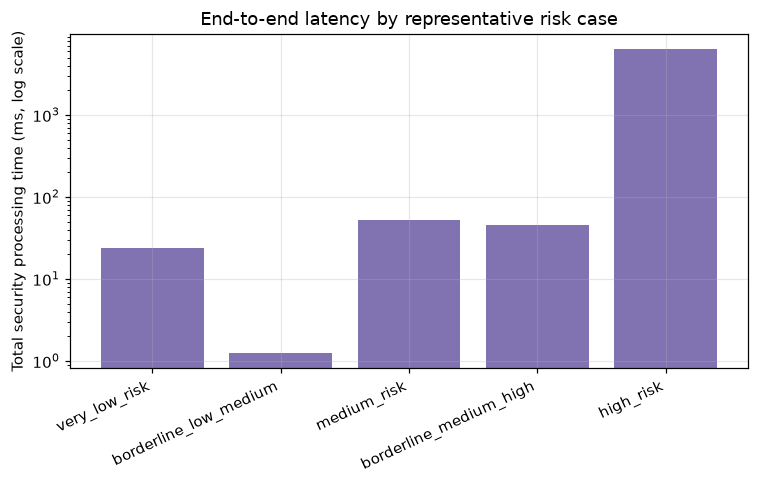

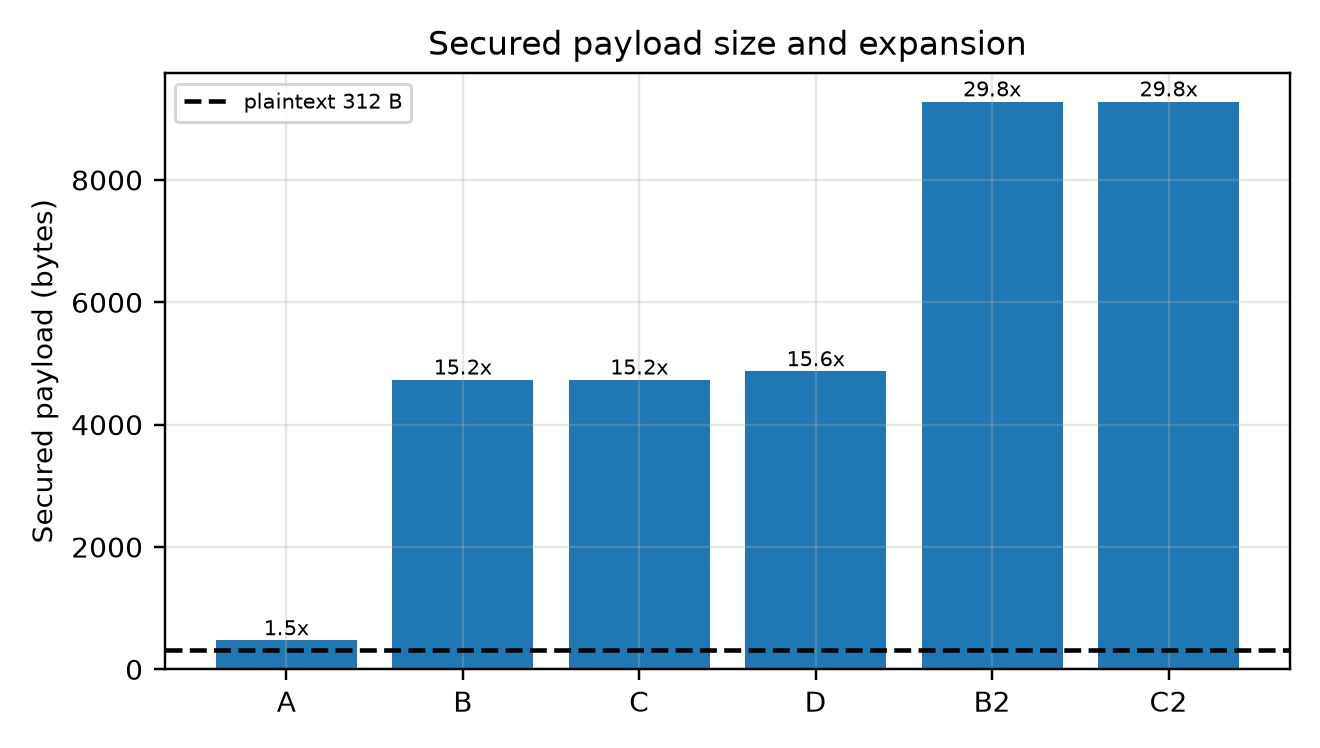

In [26]:
e2e_s = pd.read_csv(RESULTS_L2 / "end_to_end_banking_summary.csv")
display(e2e_s[e2e_s.stage=="total_end_to_end"][["config","n","median_ms","p95_ms","mean_ms","plaintext_bytes","secured_bytes","payload_expansion"]].round(3))
display(e2e_s.pivot(index="stage", columns="config", values="median_ms").round(4))
display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / "end_to_end_latency.png")))
display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / "payload_expansion.png")))

Reading the tables: the classical configuration is sub-millisecond; optimized ML-KEM-768 + ML-DSA-65 costs about ten
milliseconds per transaction (dominated by ML-DSA signing); the reference-Python version costs several times more; any
configuration using SLH-DSA-128s is dominated by its signature. Secured payload grows to roughly 15x (ML-DSA) and
roughly 30x (SLH-DSA) of the plaintext size versus about 1.5x for the classical configuration, almost entirely from KEM
ciphertext and signature bytes (see the expansion column). All numbers are taken from the tables, not from this prose.

## 35f. BB84 Final Software Statistics

Two independent implementations, same six conditions: the protocol-level simulator (100 trials at 500 and at 2,000
transmitted bits) and the Qiskit/Aer circuit simulator (50 trials at 500 bits). QBER is computed over the **full
sifted key**, $Q = N_{\mathrm{error}}/N_{\mathrm{sifted}}$; sifting efficiency
$\eta_{\mathrm{sift}} = N_{\mathrm{sifted}}/N_{\mathrm{transmitted}}$. Seeds: protocol 20000+trial, Qiskit 30000+trial.
The noise models differ by construction (protocol: one independent flip per received bit; Qiskit: bit-flip after each
single-qubit gate), so agreement is a cross-check, not an identity.

In [27]:
b = pd.read_csv(RESULTS_L2 / "bb84_final_summary.csv")
display(b[["implementation","condition","n_trials","n_transmitted","sifting_efficiency","mean_qber","median_qber","std_qber","ci95_low","ci95_high","detection_rate_at_0p11"]].round(4))
agree = json.load(open(RESULTS_L2 / "bb84_final_agreement.json"))
print({k: round(agree[k],5) for k in ("MAE","RMSE","max_abs_diff")})
pd.DataFrame(agree["per_condition"]).T.round(4)

,implementation,condition,n_trials,n_transmitted,sifting_efficiency,mean_qber,median_qber,std_qber,ci95_low,ci95_high,detection_rate_at_0p11
0,protocol_2000,clean,100,2000,0.4999,0.0000,0.0000,0.0000,0.0000,0.0000,0.00
1,protocol_2000,noise_1pct,100,2000,0.4999,0.0097,0.0099,0.0032,0.0091,0.0103,0.00
2,protocol_2000,noise_5pct,100,2000,0.4999,0.0490,0.0483,0.0069,0.0477,0.0504,0.00
3,protocol_2000,noise_10pct,100,2000,0.4999,0.0979,0.0991,0.0098,0.0960,0.0999,0.12
4,protocol_2000,eve_intercept_resend,100,2000,0.4996,0.2508,0.2492,0.0145,0.2479,0.2537,1.00
5,protocol_2000,eve_and_noise_2pct,100,2000,0.4996,0.2606,0.2589,0.0144,0.2578,0.2635,1.00
6,protocol_500,clean,100,500,0.5004,0.0000,0.0000,0.0000,0.0000,0.0000,0.00
7,protocol_500,noise_1pct,100,500,0.5004,0.0104,0.0088,0.0072,0.0090,0.0118,0.00
8,protocol_500,noise_5pct,100,500,0.5004,0.0496,0.0498,0.0128,0.0470,0.0521,0.00
9,protocol_500,noise_10pct,100,500,0.5004,0.0999,0.1000,0.0169,0.0965,0.1033,0.34


{'MAE': 0.00282, 'RMSE': 0.00363, 'max_abs_diff': 0.0065}


,protocol,qiskit,abs_diff,welch_p
clean,0.0000,0.0000,0.0000,NaN
noise_1pct,0.0104,0.0082,0.0023,0.0919
noise_5pct,0.0496,0.0498,0.0002,0.9245
noise_10pct,0.0999,0.0960,0.0039,0.2743
eve_intercept_resend,0.2503,0.2438,0.0065,0.1742
eve_and_noise_2pct,0.2609,0.2649,0.0040,0.3736


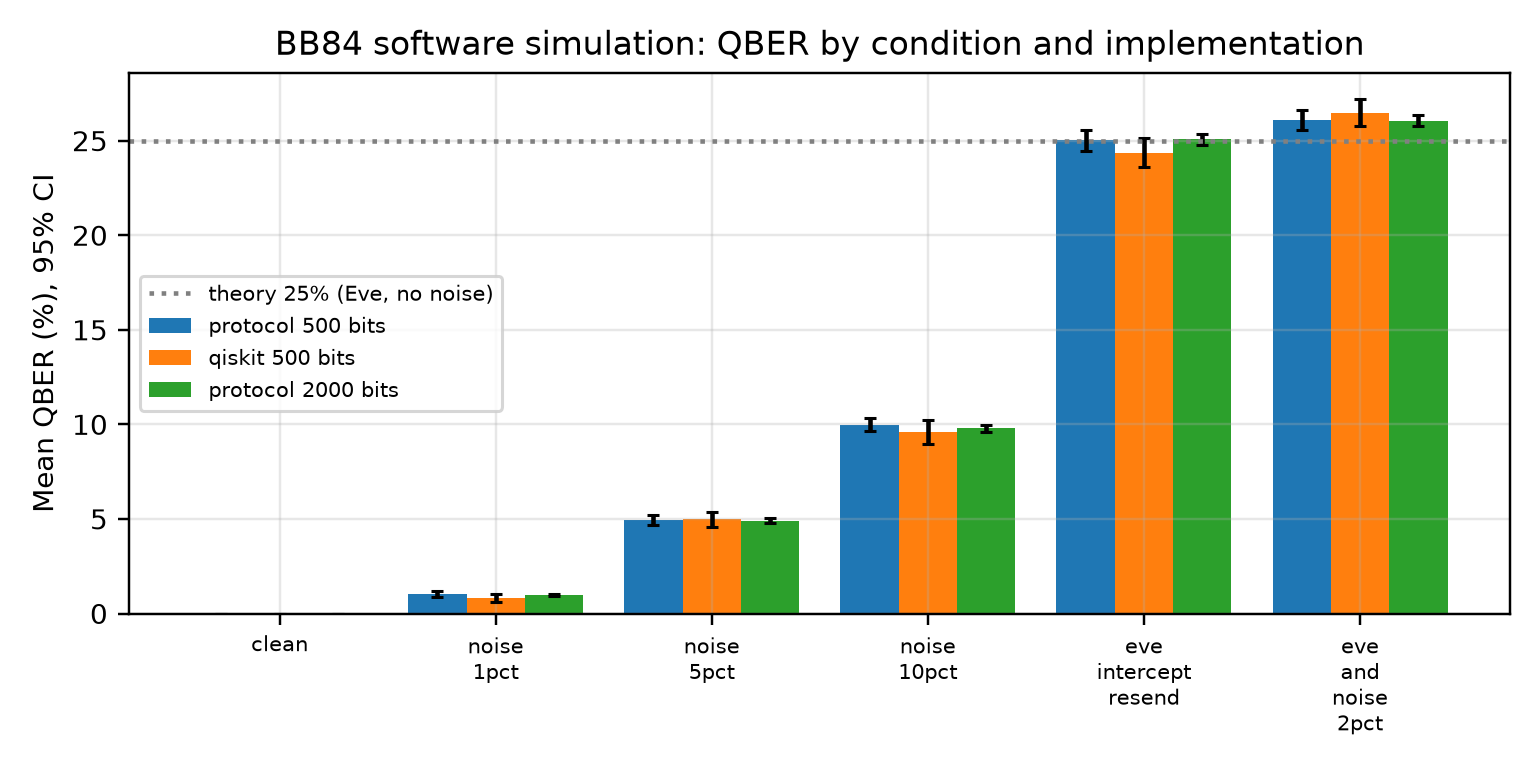

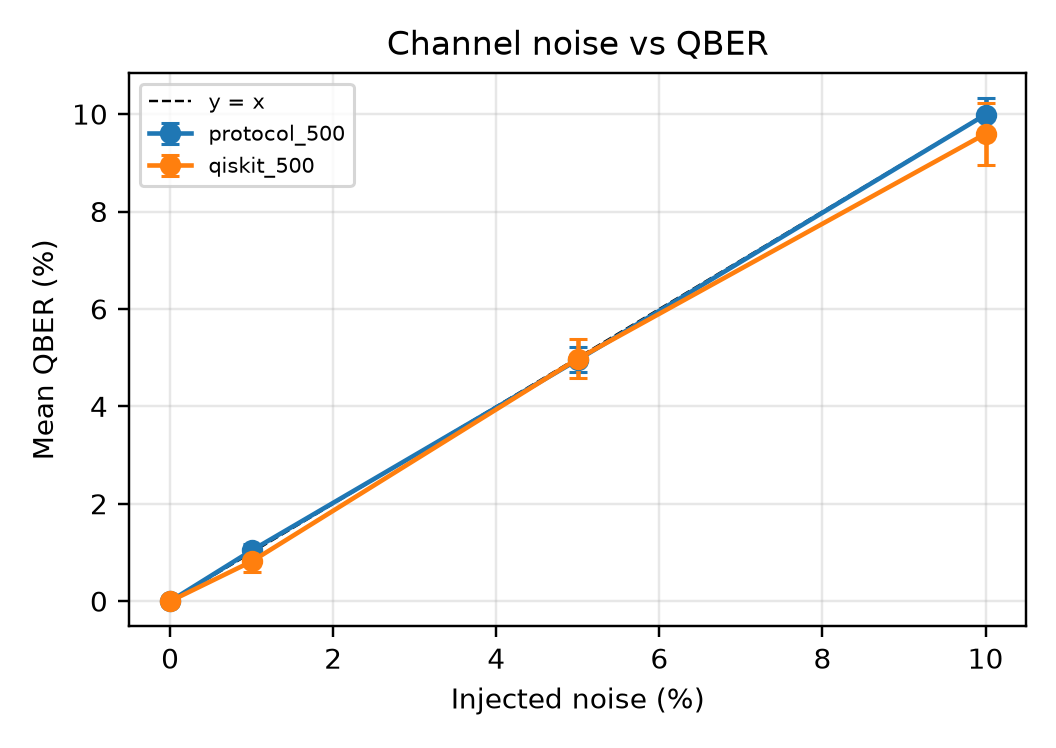

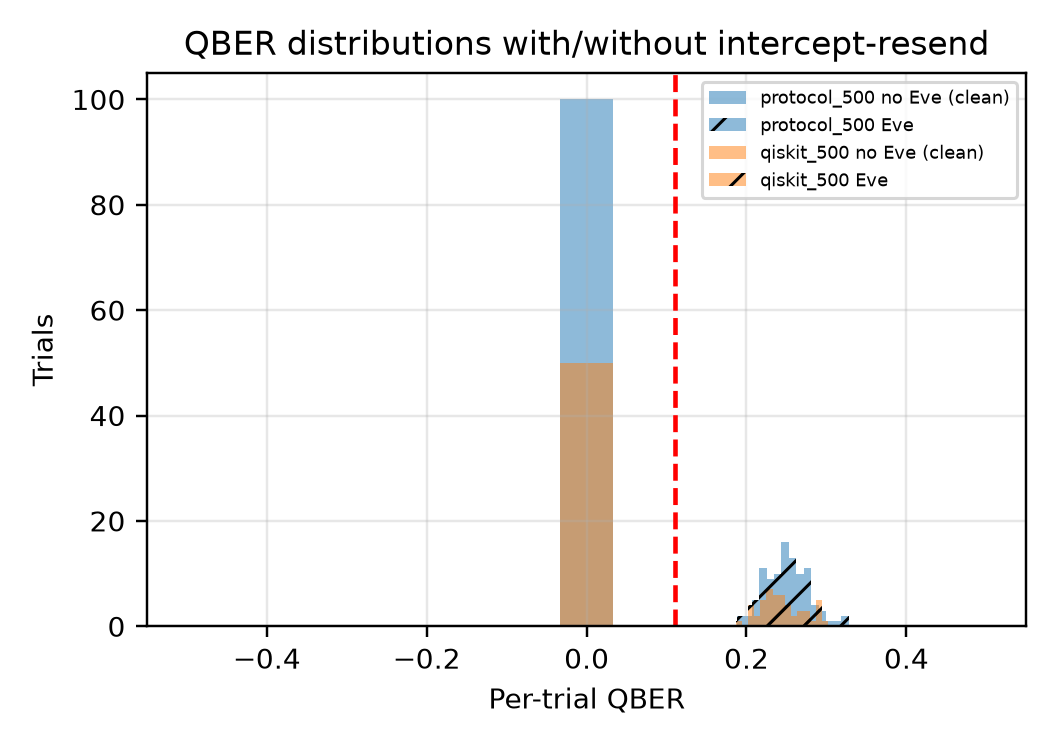

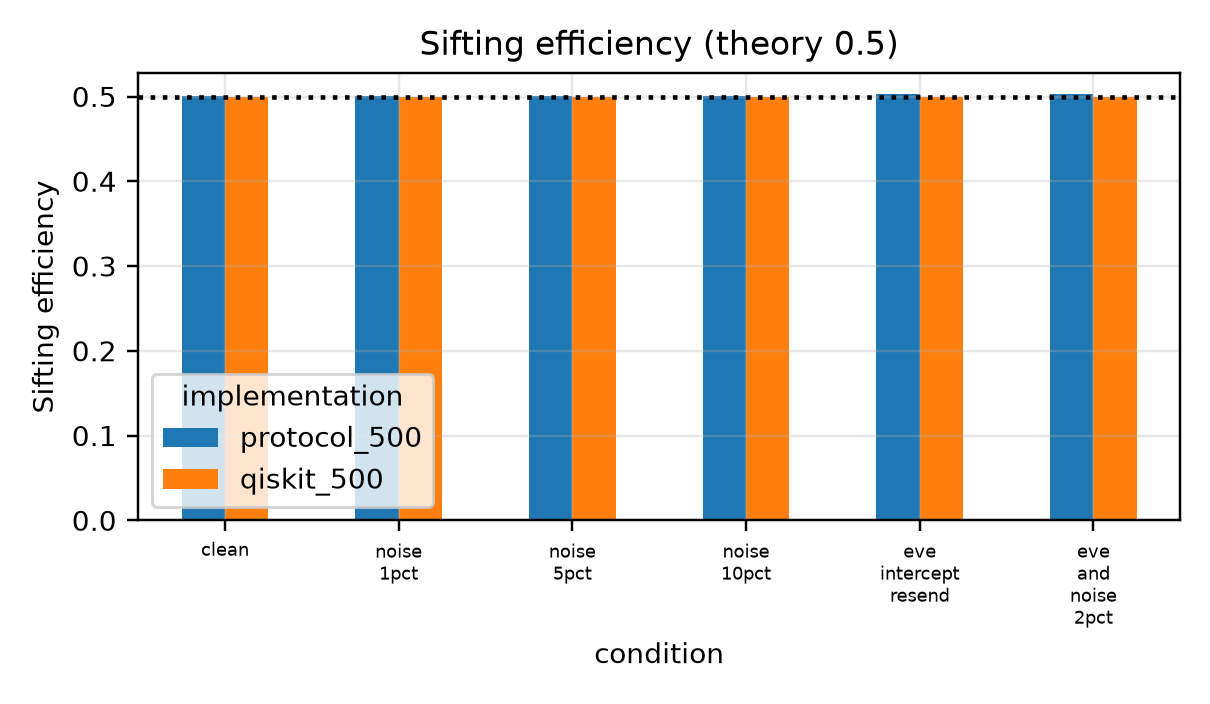

In [28]:
for f in ["bb84_final_qber_ci.png","bb84_final_noise_vs_qber.png","bb84_final_eve_distribution.png","bb84_sifting_efficiency.png"]:
    display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / f)))

**Theory check.** Clean channel: expected $Q = 0$. Intercept-resend with a random Eve basis: Eve's basis differs from
Alice's half the time, and in those events Bob's matched-basis outcome is wrong half the time, so
$Q = \tfrac12\cdot\tfrac12 = 25\%$ on the sifted key. Measured values with confidence intervals are in the table above
(they are not tuned toward 25%). Correlation of two curves is not used as evidence of equivalence; MAE, RMSE and the
maximum gap are.

## 35g. Eve-Detection Threshold Analysis

A threshold sweep (0.00 to 0.40) is evaluated on per-trial QBER. Negatives are Eve-absent trials; positives are
Eve-present trials. Two negative sets are reported because the false-positive rate depends on which noise levels count
as benign: (i) clean + 1% + 5% + 10% noise, (ii) clean + 1% + 5% noise. The 0.11 value is a conventional
security-theory figure; here it is only a **simulation-specific decision rule**. High channel noise also raises QBER, so
a QBER above a threshold does **not** prove an eavesdropper.

,implementation,negatives,TPR_at_0p11,FPR_at_0p11,miss_at_0p11,BA_at_0p11,first_best_threshold,best_BA
0,protocol_2000,no_eve_all_noise_levels,1.0,0.030,0.0,0.985,0.12,1.0
1,protocol_2000,no_eve_clean_to_5pct,1.0,0.000,0.0,1.000,0.07,1.0
2,protocol_500,no_eve_all_noise_levels,1.0,0.085,0.0,0.958,0.14,1.0
3,protocol_500,no_eve_clean_to_5pct,1.0,0.000,0.0,1.000,0.08,1.0
4,qiskit_500,no_eve_all_noise_levels,1.0,0.055,0.0,0.972,0.16,1.0
5,qiskit_500,no_eve_clean_to_5pct,1.0,0.000,0.0,1.000,0.09,1.0


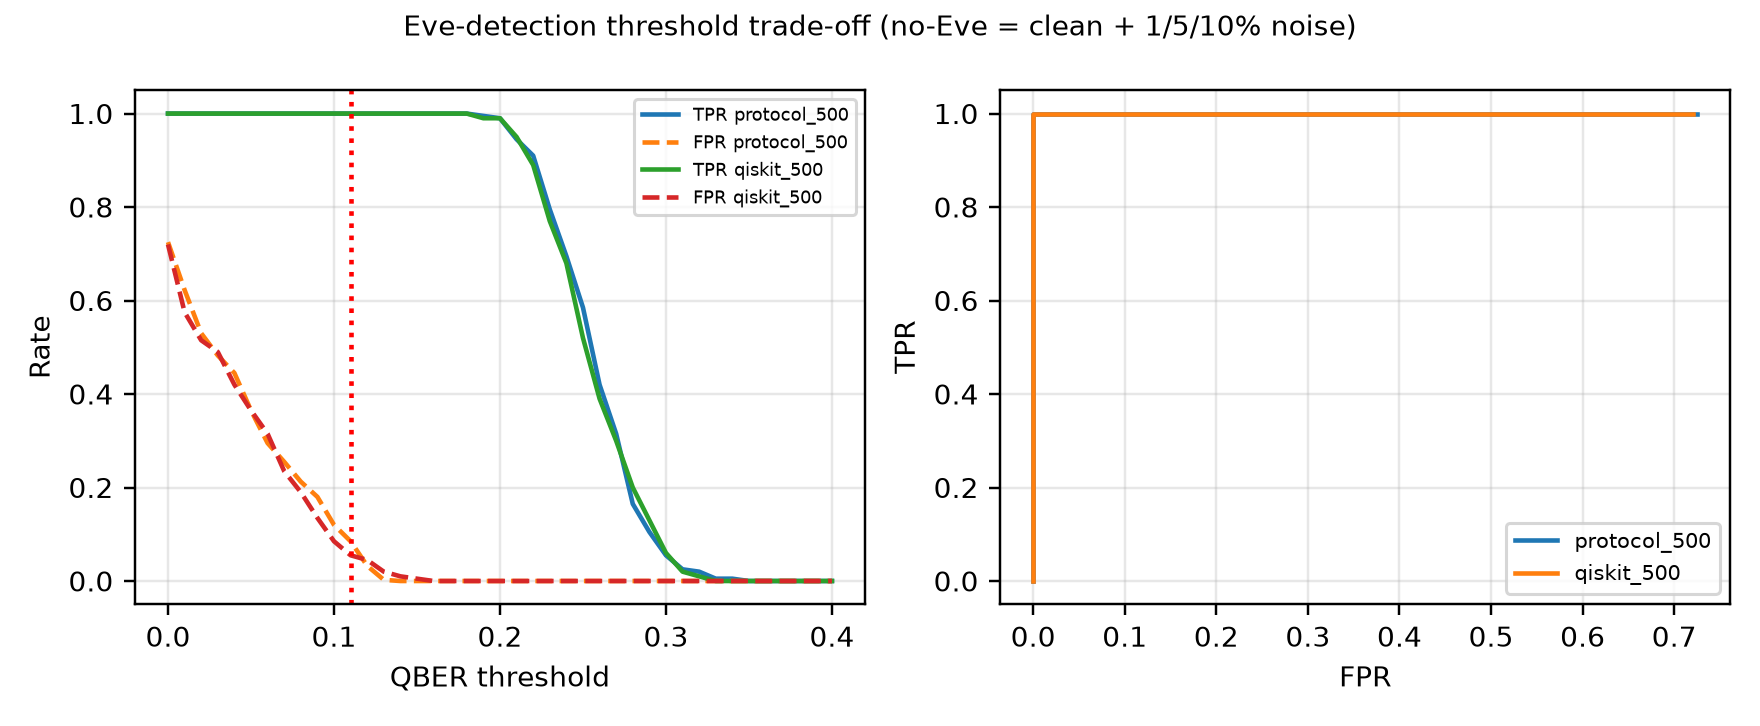

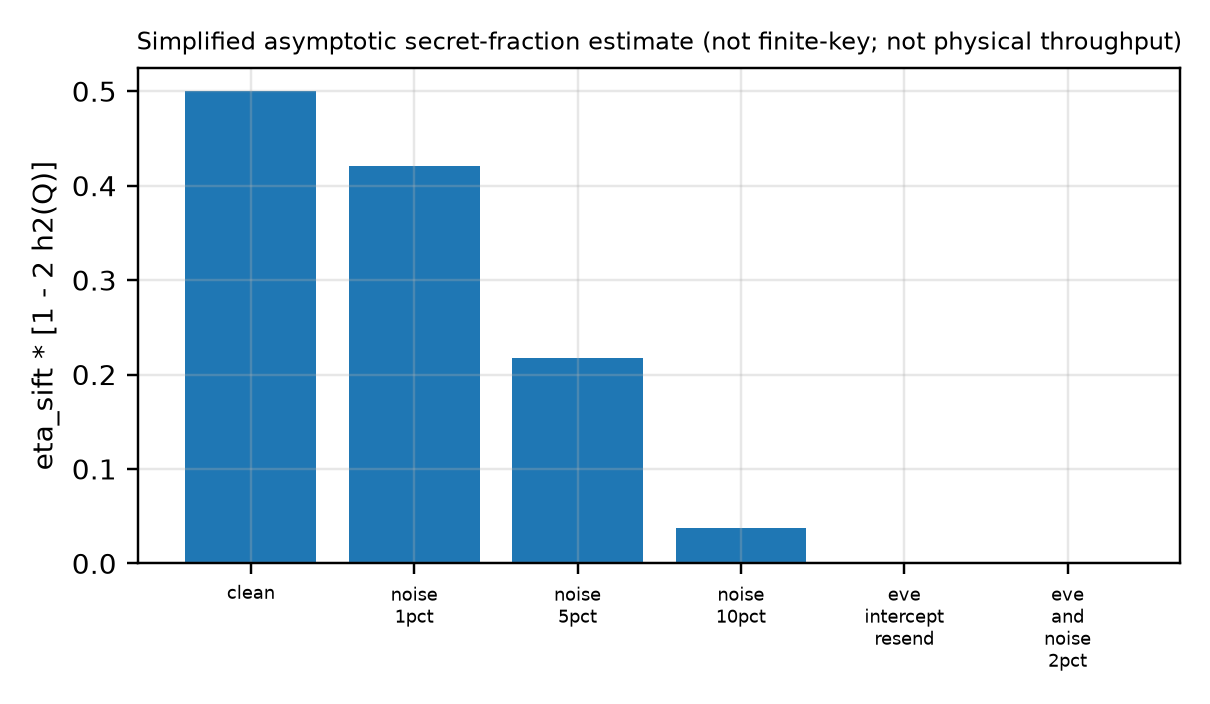

In [29]:
sw = pd.read_csv(RESULTS_L2 / "bb84_threshold_sweep.csv")
rows = []
for (im, neg), d in sw.groupby(["implementation","negatives"]):
    r = d[np.isclose(d.threshold, 0.11)].iloc[0]; best = d.loc[d.balanced_accuracy.idxmax()]
    rows.append(dict(implementation=im, negatives=neg, TPR_at_0p11=r.TPR, FPR_at_0p11=r.FPR, miss_at_0p11=r.miss_rate, BA_at_0p11=r.balanced_accuracy, first_best_threshold=best.threshold, best_BA=best.balanced_accuracy))
display(pd.DataFrame(rows).round(3))
display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / "bb84_threshold_tradeoff.png")))
display(Image(str(ROOT / "artifacts" / "figures" / "layer2" / "bb84_key_rate_estimate.png")))

At 0.11 every Eve-present trial is flagged (TPR = 1.0) in all three data sets, but Eve-absent trials at 10% noise
produce false alarms because their QBER sits near the threshold, so FPR at 0.11 is non-zero when 10% noise is counted
as benign. A somewhat higher threshold separates the classes completely **in these simulated conditions**; that
optimum depends on the chosen noise range and is not claimed as a general security threshold. The key-rate figure is a
simplified asymptotic estimate $\eta_{\mathrm{sift}}[1-2h_2(Q)]$, not a finite-key proof and not physical throughput.

## 35h. IBM Quantum Hardware Validation (saved artifacts only)

All hardware results below are loaded from saved raw counts and calibration snapshots. **This notebook never submits
IBM jobs.** Three levels are kept distinct: theory, software simulation (ideal Aer and backend-derived noisy Aer), and
real IBM Quantum hardware (`ibm_marrakesh`, plus an earlier QML-circuit run on `ibm_fez`). The first `ibm_marrakesh`
job (`db2u94vr11fs7397g1u0`) is a **pilot / hardware baseline**; headline statistics come from the replicated
campaign. The BB84 circuits are circuit-level hardware validation of preparation and measurement primitives and are
**not physical QKD** (no photons, no communicating parties).

In [30]:
IBM = ROOT / "results" / "ibm_quantum"
hs = json.load(open(IBM / "hardware_statistics.json"))
print("backend", hs["backend"], "| independent jobs", hs["n_jobs"], "| shots/circuit", hs["shots_per_circuit"]); print("job IDs:", hs["job_ids"])
display(pd.read_csv(IBM / "hardware_backend_table.csv").round(4))
display(pd.read_csv(IBM / "hardware_calibration_table.csv").round(5))

backend ibm_marrakesh | independent jobs 5 | shots/circuit 2048
job IDs: ['db2ugk42ljfc73d57mi0', 'db2ukr42ljfc73d57ttg', 'db2ul8u8v0ts73c3j3i0', 'db2ulj7r11fs7397go30', 'db2ulu42ljfc73d57vl0']


,experiment,qubit,theory,ideal_aer,noisy_aer,hardware_mean,ci95_low,ci95_high,independent_jobs,backend
0,BB84 matched-basis QBER (no Eve),best (q98),0.00,0.00,0.0025,0.0048,0.0036,0.0060,5,ibm_marrakesh
1,Intercept-resend QBER,best (q98),0.25,0.25,0.2512,0.2632,0.2579,0.2685,5,ibm_marrakesh
2,BB84 matched-basis QBER (no Eve),typical (q155),0.00,0.00,0.0110,0.0094,0.0082,0.0106,5,ibm_marrakesh
3,Intercept-resend QBER,typical (q155),0.25,0.25,0.2557,0.2591,0.2535,0.2648,5,ibm_marrakesh
4,BB84 matched-basis QBER (no Eve),worse (q126),0.00,0.00,0.0738,0.0446,0.0277,0.0616,5,ibm_marrakesh
5,Intercept-resend QBER,worse (q126),0.25,0.25,0.2873,0.2868,0.2796,0.2939,5,ibm_marrakesh
6,Grover 2q success probability,"pair [135, 139]",1.00,1.00,0.9678,0.9460,0.9386,0.9534,5,ibm_marrakesh


,role,physical_qubit,T1_us,T2_us,readout_error,sx_error,measure_duration_us,circuit_type,observed_no_eve_QBER,observed_intercept_resend_QBER
0,best,98,265.63318,68.84836,0.00208,0.00082,2.684,BB84 single-qubit,0.00479,0.26320
1,typical,155,393.90483,106.95003,0.01221,0.00035,2.684,BB84 single-qubit,0.00940,0.25913
2,worse,126,104.25381,8.64592,0.07593,0.00044,2.684,BB84 single-qubit,0.04463,0.28678
3,grover_pair,135,294.54046,91.05853,0.02295,0.00011,2.684,Grover 2q (cz err 0.0011),NaN,NaN
4,grover_pair,139,136.29793,158.94027,0.00537,0.00019,2.684,Grover 2q (cz err 0.0011),NaN,NaN


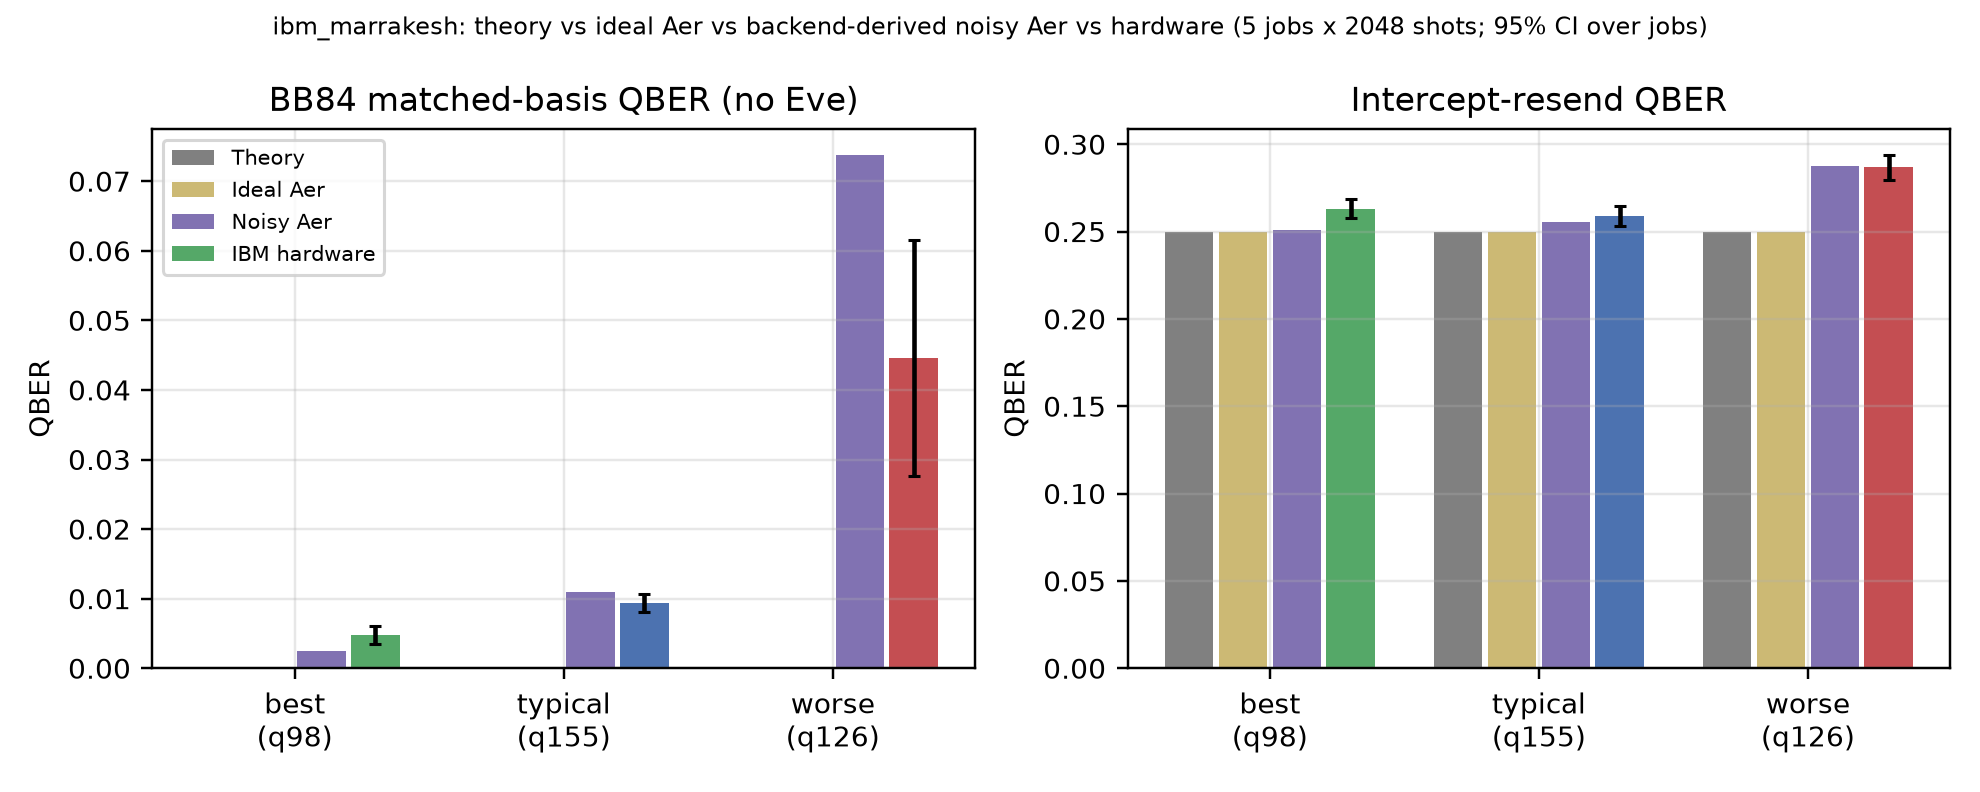

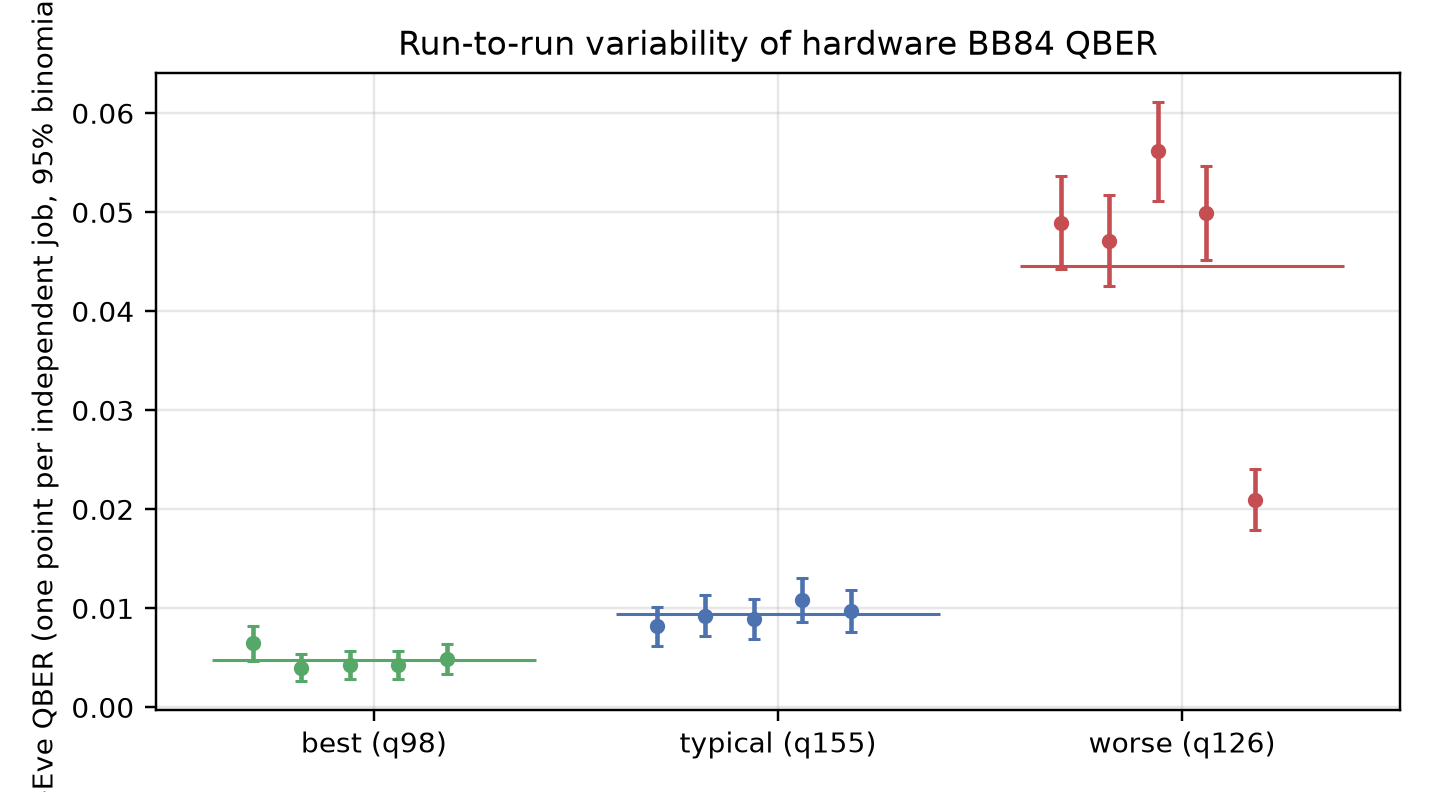

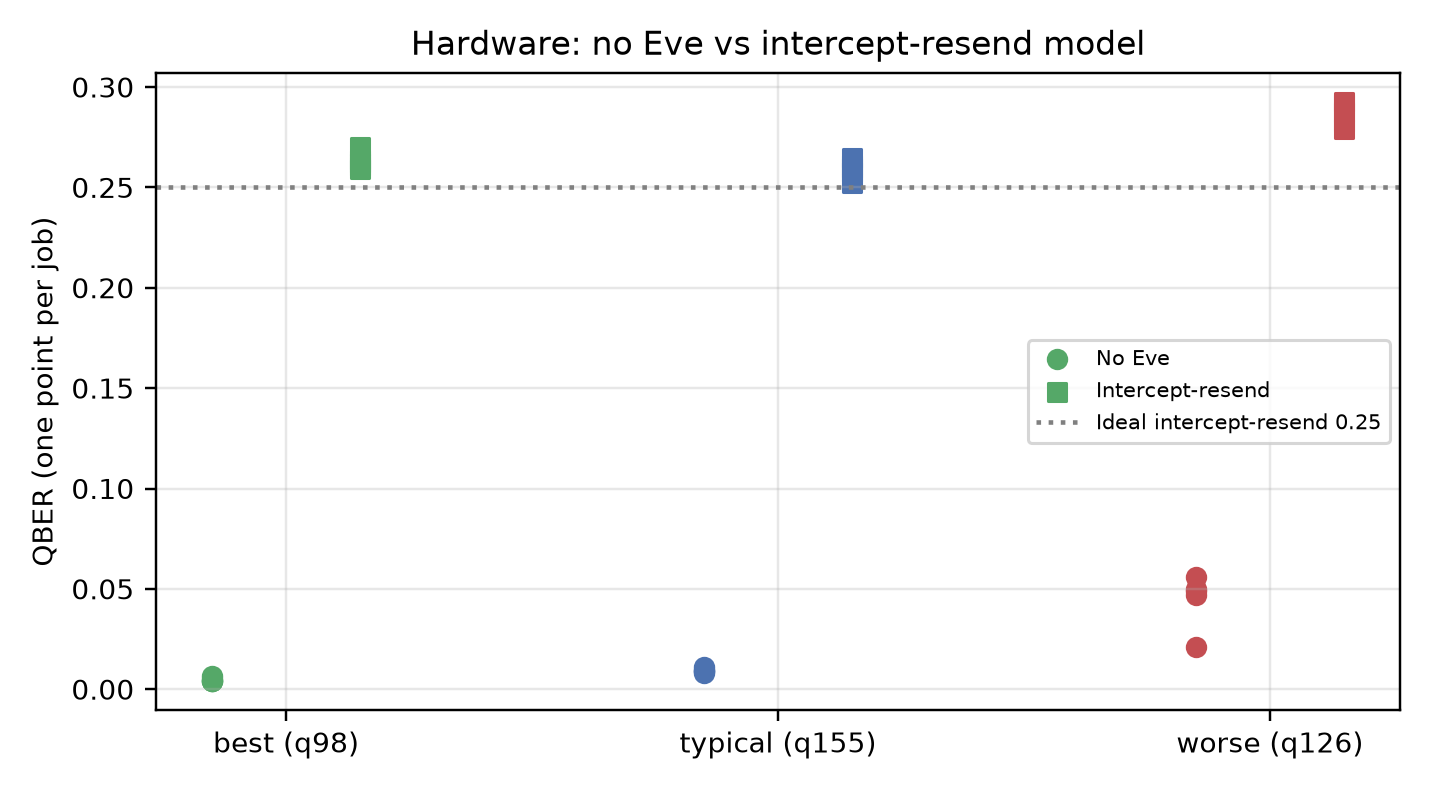

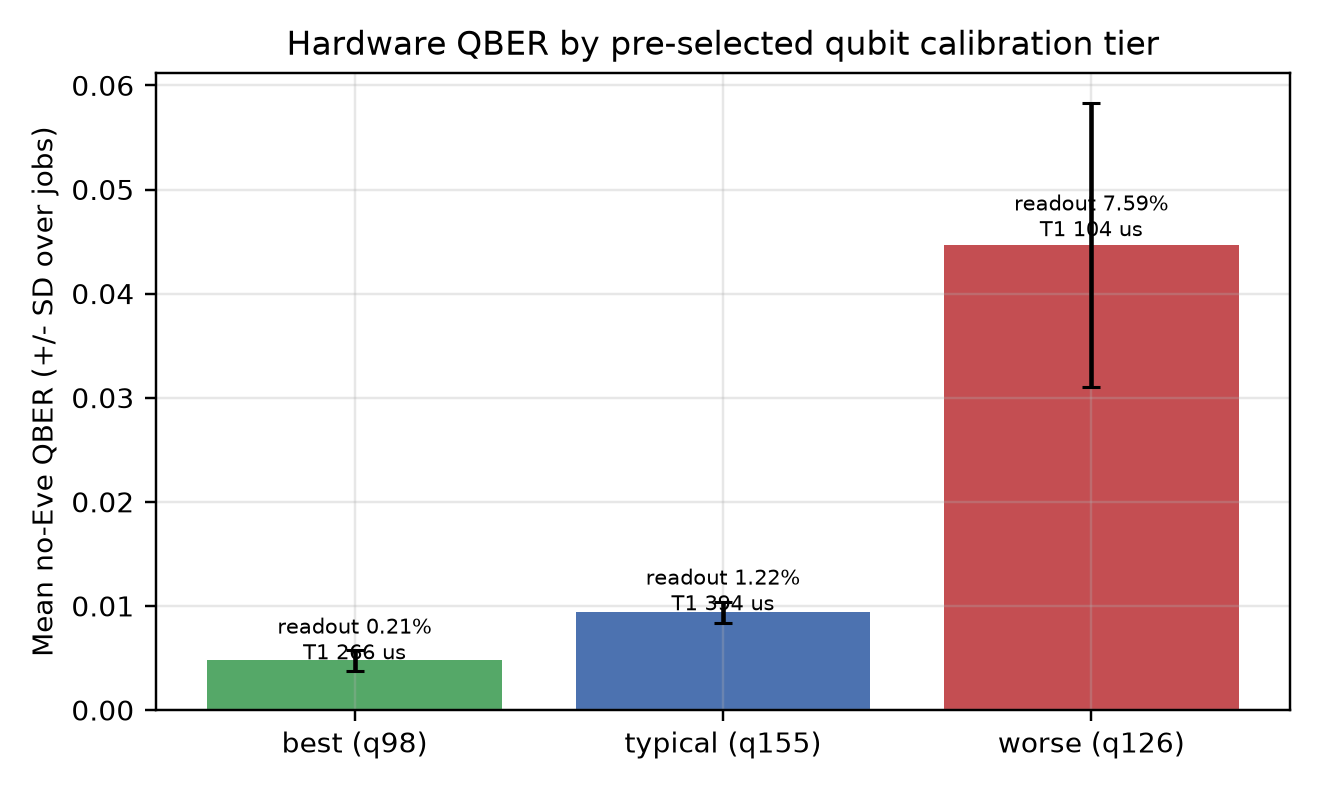

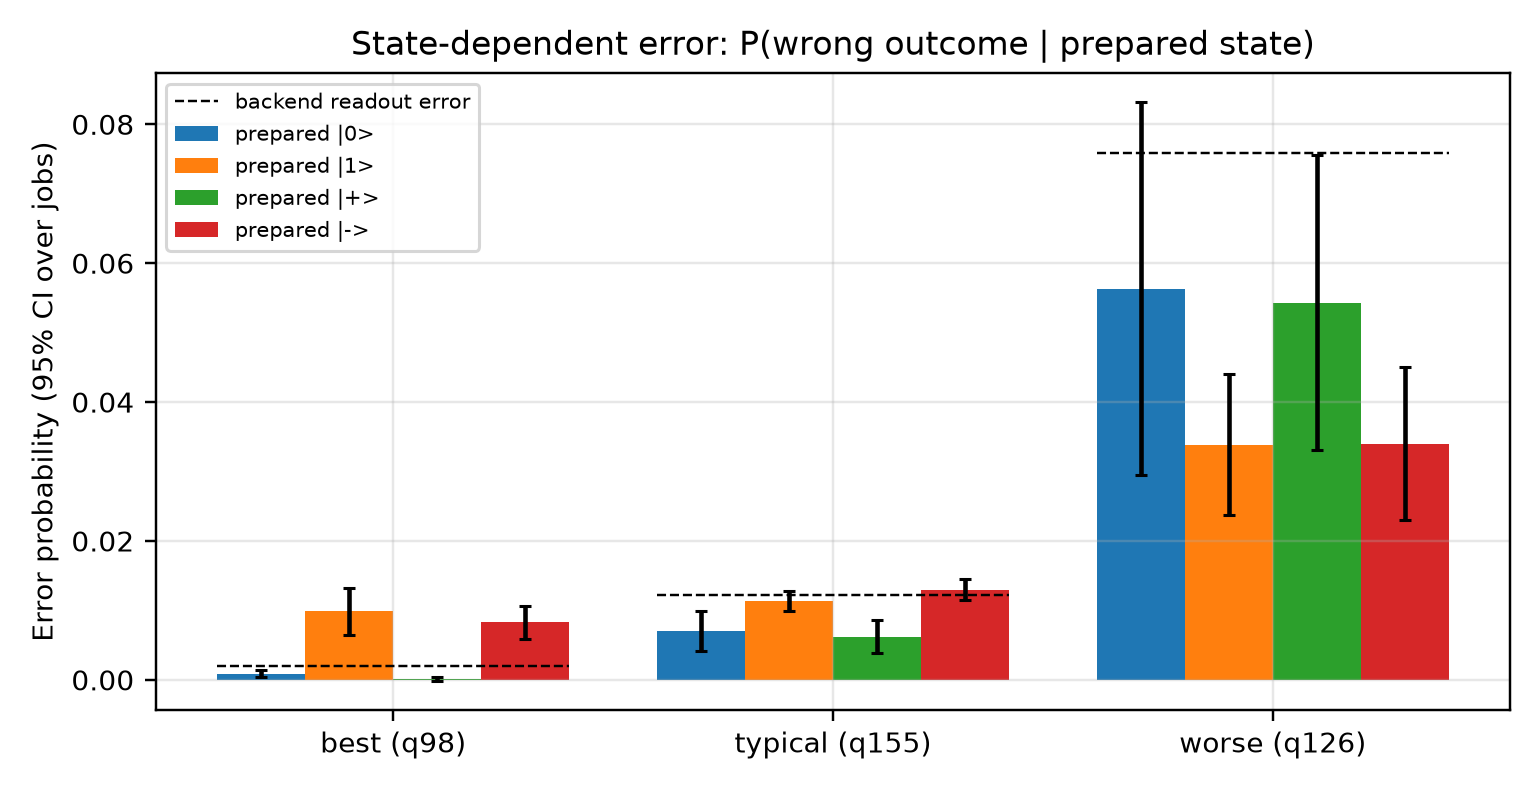

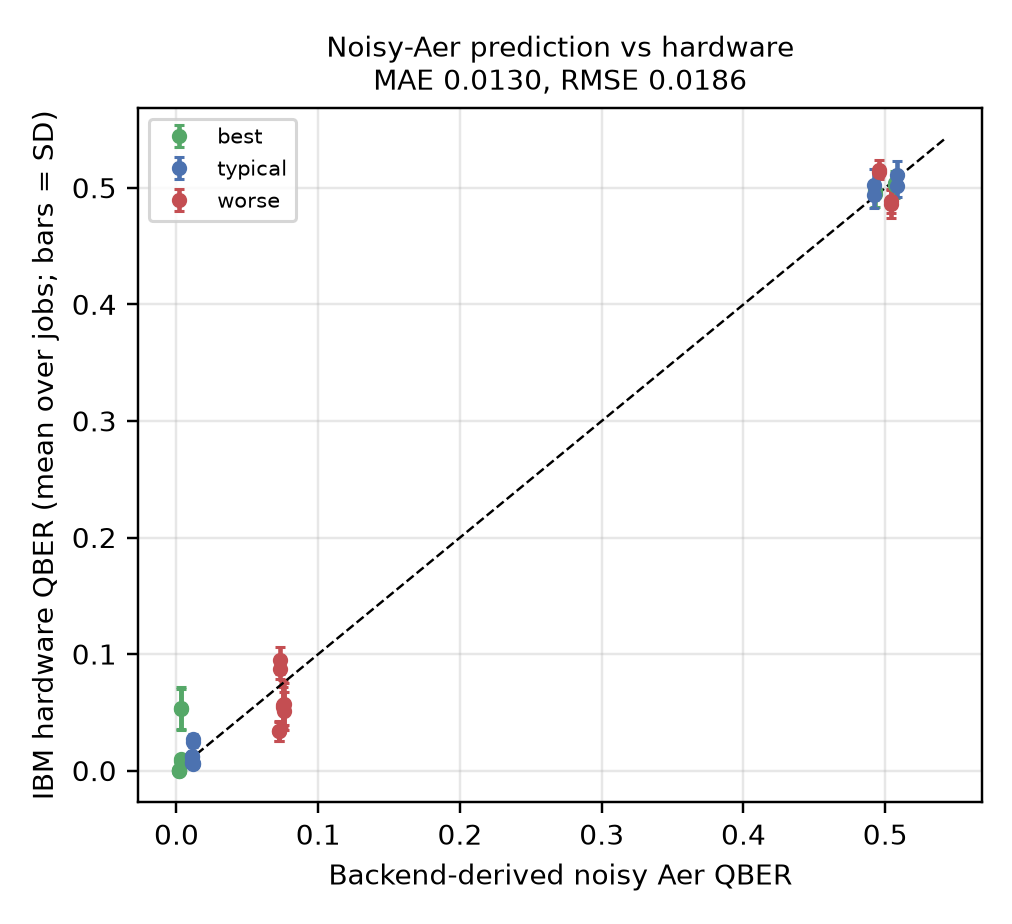

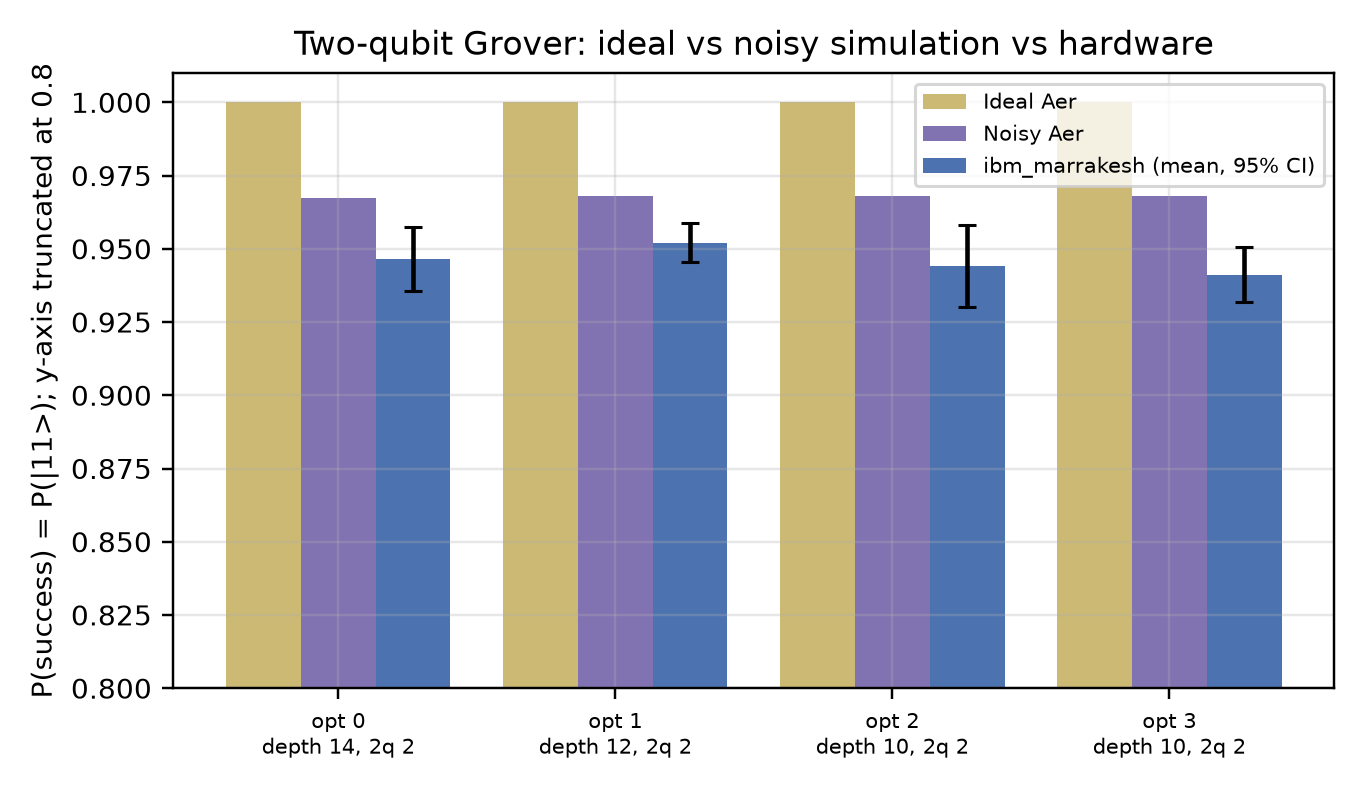

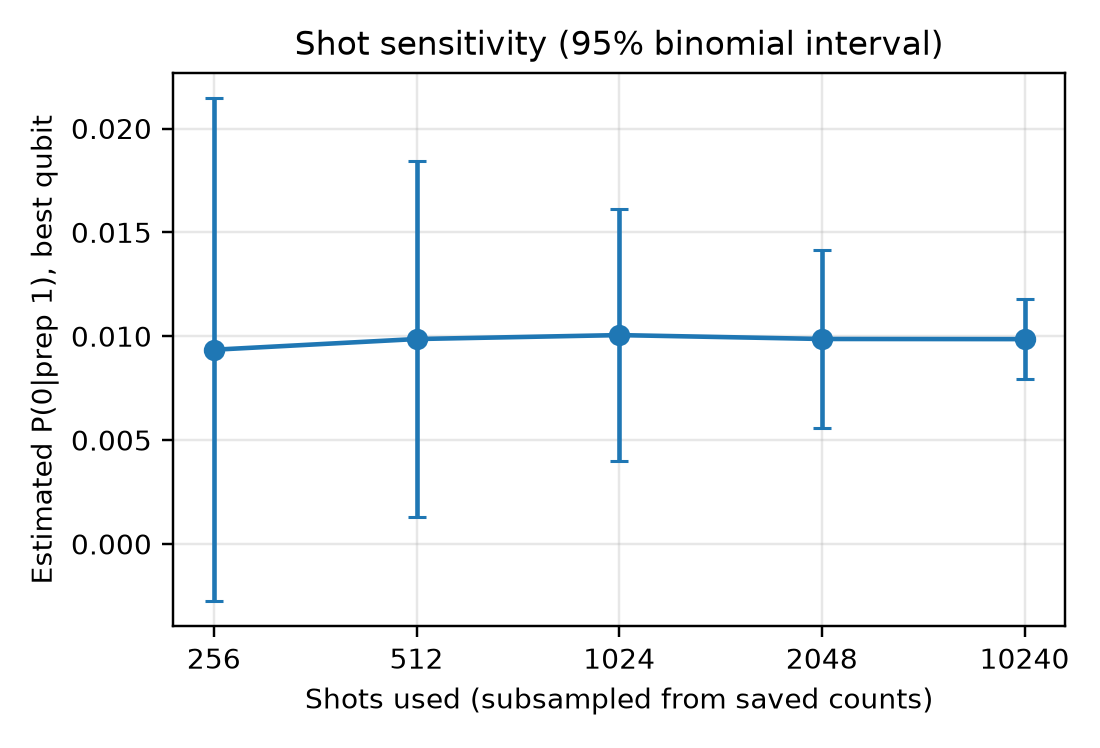

In [31]:
for f in ["hw_qber_theory_ideal_noisy_hardware.png","hw_qber_per_job.png","hw_eve_vs_noeve.png","hw_qber_by_qubit_quality.png","hw_state_asymmetry.png","hw_noisy_aer_vs_hardware.png","hw_grover_success.png","hw_shot_sensitivity.png"]:
    display(Image(str(ROOT / "artifacts" / "figures" / "ibm_quantum" / f)))

In [32]:
print(json.dumps({k: hs[k] for k in ("eve_vs_no_eve","eve_noeve_separation","state_asymmetry_Z","state_asymmetry_cells_consistent","noisy_aer_prediction")}, indent=1)[:3500])
print(json.dumps(hs["qubit_quality"], indent=1)[:1500])
display(pd.read_csv(IBM / "hardware_grover_summary.csv").round(4))

{
 "eve_vs_no_eve": {
  "best": {
   "label": "best qubit, paired by job",
   "n_pairs": 5,
   "mean_delta": 0.25841064453125,
   "bootstrap_ci95": [
    0.2558349609375,
    0.2614501953125
   ],
   "sign_flip_permutation_p_one_sided": 0.03125,
   "min_attainable_p": 0.03125,
   "cohens_dz": 72.80526715499943,
   "all_deltas_positive": true
  },
  "typical": {
   "label": "typical qubit, paired by job",
   "n_pairs": 5,
   "mean_delta": 0.2497314453125,
   "bootstrap_ci95": [
    0.24591064453125,
    0.2525634765625
   ],
   "sign_flip_permutation_p_one_sided": 0.03125,
   "min_attainable_p": 0.03125,
   "cohens_dz": 58.5572858821292,
   "all_deltas_positive": true
  },
  "worse": {
   "label": "worse qubit, paired by job",
   "n_pairs": 5,
   "mean_delta": 0.24215087890625,
   "bootstrap_ci95": [
    0.2356201171875,
    0.2505859375
   ],
   "sign_flip_permutation_p_one_sided": 0.03125,
   "min_attainable_p": 0.03125,
   "cohens_dz": 24.664702449844697,
   "all_deltas_positive": tr

,opt_level,n_jobs,mean_success,std,ci95_low,ci95_high,min,max,ideal_aer_success,noisy_aer_success,transpiled_depth,two_qubit_gates,one_qubit_gates,hw_minus_ideal,hw_minus_noisy
0,0,5,0.9465,0.0087,0.9357,0.9573,0.9375,0.9609,1.0,0.9673,14,2,22,-0.0535,-0.0208
1,1,5,0.9521,0.0054,0.9454,0.9589,0.9443,0.9595,1.0,0.9680,12,2,18,-0.0479,-0.0159
2,2,5,0.9441,0.0112,0.9303,0.9580,0.9307,0.9575,1.0,0.9680,10,2,12,-0.0559,-0.0239
3,3,5,0.9412,0.0075,0.9318,0.9506,0.9336,0.9517,1.0,0.9680,10,2,12,-0.0588,-0.0268


In [33]:
fez = json.load(open(ROOT / "reports" / "ibm_hardware" / "hardware_run.json"))["hardware_experiment"]
print("ibm_fez QML circuit run:", fez["backend"], fez["job_id"], "shots", fez["shots"])
for k, v in fez["candidates"].items():
    h, s_ = np.array(v["hardware_expectation_values"]), np.array(v["simulator_expectation_values"])
    print(k, "n_tx", len(h), "depth", v["logical_depth"], "->", v["transpiled_depth"], "| mean|hw-sim|", round(v["mean_abs_deviation"],3), "| Pearson r", round(float(np.corrcoef(h, s_)[0,1]),3))

ibm_fez QML circuit run: ibm_fez da6ejl46l22c73dm82ng shots 1024
clt n_tx 6 depth 21 -> 45 | mean|hw-sim| 0.229 | Pearson r 0.435
generic n_tx 6 depth 23 -> 47 | mean|hw-sim| 0.417 | Pearson r 0.16


**What this establishes and does not establish.** Hardware adds measurable error over both simulators, the amount
depends on the physical qubit's calibration tier, and the backend-derived noisy simulation tracks but does not exactly
reproduce the hardware results (MAE/RMSE above). The intercept-resend circuit model stays clearly distinguishable from
no-Eve hardware error. State-dependent error asymmetry is *consistent with relaxation and asymmetric readout effects*;
a unique causal mechanism is not established. The two-qubit Grover circuit loses some success probability on hardware;
it is an educational NISQ demonstration with **no implication for AES or RSA key sizes**. Shor's algorithm is not
implemented. Only selected circuits were executed on IBM hardware, not the full QSFD fraud classifier, and results
depend on backend, calibration, qubit mapping and execution time.

## 38. Negative Results (Consolidated)

| Finding | Section |
|---|---|
| Categorical vs continuous routing: no difference on this dataset | 24-29 |
| Anomaly-assisted routing adds cost without adding fraud coverage | 24-29 |
| Quantum-assisted routing fails its own pre-specified cost budget by 16x | 30 |
| HYBRID_MAXIMUM/QKD_EXPERIMENTAL cost ~4-6+ seconds, dominated by SLH-DSA | 21, 36-37 |
| SLH-DSA-SHA2-128s signing stays ~1 s even with a compiled backend (pqcrypto), ~100x ML-DSA-65: mostly a parameter-set cost, partly implementation | 14, 35c |
| Native `liboqs` PQC backend unavailable in this environment (no C/CMake toolchain) | 35b |

## 39. Scientific Contribution

A working implementation and empirical benchmark of classical (AES-256-GCM, RSA-3072, ECC/P-256), standardized
post-quantum (ML-KEM-768, ML-DSA-65, SLH-DSA-SHA2-128s), and simulated-QKD-oriented (BB84) security components,
integrated into a risk-adaptive pipeline driven by real Layer 1 fraud intelligence via a model-agnostic contract.
The integration experiment provides a **quantified, reproducible answer** (not an assumed one) to whether
richer Layer 1 signals improve Layer 2 routing: for anomaly and quantum-auxiliary signals specifically, on this
data, they do not clear a pre-specified cost bar.

## 40. Limitations

See `docs/research/layer2/LAYER2_LIMITATIONS.md` and
`docs/research/integration/LAYER1_LAYER2_INTEGRATION_EXPERIMENT_RESULTS.md` for the full itemized lists —
summarized: pure-Python PQC performance is not production-representative and a native `liboqs` backend could not
be installed in this environment (no C/CMake toolchain); no concurrency/load testing exists; the policy
ablation's null result for categorical-vs-continuous may be dataset-specific; Policy D's sample is small (n=250);
the Qiskit BB84 cross-validation used a reduced per-trial bit count (200 vs. 2000) to bound simulator overhead.

## 41. Layer 2 Conclusion

Classical, post-quantum, and simulated-QKD security components are implemented, tested, and benchmarked. The
risk-adaptive integration with Layer 1 works end-to-end and is auditable. Of the two "richer signal" hypotheses
tested (anomaly-assisted and quantum-assisted routing), **neither is supported by the evidence** at their tested
configurations — both add cost without a correspondingly defensible fraud-coverage gain. Categorical and
continuous routing are equally effective on this dataset. No claim of quantum advantage, quantum supremacy, or
physical QKD security is made.

### What Layer 2 Establishes / Does Not Establish

| Establishes | Does Not Establish |
|---|---|
| Classical + standardized PQC (ML-KEM/ML-DSA/SLH-DSA) can be integrated into a common transaction-security architecture | Universal PQC algorithm performance (pure-Python only) |
| BB84 simulator reproduces expected eavesdropping/noise behavior under stated conditions (30/30 detection) | Physical QKD security or hardware quantum communication |
| An independent Qiskit circuit implementation cross-validates the protocol-level BB84 simulator (agreement within 0.62 pp across 6 conditions) | That circuit-level simulation is physical QKD -- it is not |
| Fraud risk and cryptographic-quantum-threat posture must be modeled as separate axes | Risk-adaptive security is universally ineffective (only tested configurations failed their cost budget) |
| Real, repeated-measurement cryptographic benchmarks characterize genuine PQC migration cost | That this cost is representative of optimized/native PQC implementations (native `liboqs` backend attempted, unavailable in this environment) |

## 42. Layer 3 — Future Work

Explicitly not implemented in this project: MITM, replay, brute-force, and adversarial ML (evasion/poisoning)
attack simulations; Shor's and Grover's algorithm demonstrations against production-scale keys (Shor threatens
RSA/ECC asymptotically; Grover halves effective symmetric-key search strength — neither is demonstrated against
real production key sizes in this project, nor should such a claim ever be made without a genuine experiment);
QKD-specific attack extensions beyond intercept-resend; formal cryptographic migration-risk analysis. These
remain future work, deliberately deferred so Layers 1 and 2 could be completed to a defensible standard first.

---
*Generated by `scripts/notebooks/build_notebook_2.py`, executed by `scripts/notebooks/execute_notebooks.py`.*